# 3. Fase predictiva: Modelo predictivo de ocurrencia

Esta etapa tiene como finalidad entrenar, evaluar y visualizar un modelo de ocurrencia de accidentes viales a partir del conjunto de datos integrado en la fase previa, empleando un enfoque de SML basado en un ensamble de Random Forest con esquema temporal, calibración *post hoc* mediante Regresión Isotónica e Inteligencia Artificial Explicable .

## 1. Configuración y librerías

In [1]:
import sys
import subprocess

# Diccionario con el nombre del módulo al importar y el nombre del paquete en pip
librerias_requeridas = {
    'pandas': 'pandas',
    'geopandas': 'geopandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'numpy': 'numpy',
    'sklearn': 'scikit-learn',
    'shap': 'shap',
    'joblib': 'joblib'
}

# Verificación e instalación dinámica
for modulo, paquete in librerias_requeridas.items():
    try:
        __import__(modulo)
    except ImportError:
        print(f"La librería '{modulo}' no se encontró. Iniciando instalación...")
        # Ejecuta el comando pip install usando el ejecutable actual de Python
        subprocess.check_call([sys.executable, "-m", "pip", "install", paquete])
        print(f"{modulo} se instaló exitosamente.")

# Imports estándar
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
from matplotlib.ticker import PercentFormatter
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, StratifiedShuffleSplit
from sklearn.metrics import precision_recall_curve, brier_score_loss, confusion_matrix, classification_report
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.isotonic import IsotonicRegression
import shap
import json
import os
import joblib

# Configuración del notebook
pd.set_option('display.max_columns', None)

print("Configuración inicial completada. Todo listo para trabajar.")

Configuración inicial completada. Todo listo para trabajar.


## 2. Lectura de datos

In [2]:
# Cargar los datos de accidentes
df_acc = pd.read_parquet("Generados/accidentes_franjas.parquet")
print("Datos de accidentes cargados")
display(df_acc.head(4))
print(df_acc.info())

Datos de accidentes cargados


,ID_ACC,ID_RED,FECHA_FRANJA,DIASEMANA
0,0,663941,2019-01-03 00:00:00,3
1,1,549969_2,2019-01-03 06:00:00,3
2,2,4454776,2019-01-03 06:00:00,3
3,3,2617146,2019-01-03 12:00:00,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19168 entries, 0 to 19167
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ID_ACC        19168 non-null  Int16         
 1   ID_RED        19168 non-null  object        
 2   FECHA_FRANJA  19168 non-null  datetime64[ns]
 3   DIASEMANA     19168 non-null  Int8          
dtypes: Int16(1), Int8(1), datetime64[ns](1), object(1)
memory usage: 393.2+ KB
None


In [3]:
# Cargar los datos de la red vial
gdf_rnc = gpd.read_parquet("Generados/rnc_ags.parquet")
print("Datos de la red vial cargados")
display(gdf_rnc.head(4))
print(gdf_rnc.info())

Datos de la red vial cargados


,ID_RED,ID_CENTRO,CARRILES,NIVEL,VELOCIDAD,LONGITUD,UNION_INI,UNION_FIN,AVENIDA,BOULEVARD,CALLE,CAMINO,CARRETERA,CIRCUITO,GLORIETA,INCORPORACION,PRIVADA,RETORNO_U,MENOR,CERRADA_EN_AMBOS_SENTIDOS,DOS_SENTIDOS,UN_SENTIDO,GRADO_MIN,GRADO_MAX,DIST_NODO_3,DIST_NODO_4,DIST_NODO_5_MAS,SINUOSIDAD,DIST_MAN_PROH,DELTA_CARRILES_MAX,DELTA_CARRILES_MIN,DELTA_CARRILES_MEAN,DELTA_VELOCIDAD_MAX,DELTA_VELOCIDAD_MIN,DELTA_VELOCIDAD_MEAN,geometry
0,358174,322,2,0,80,19.447878,1172947,1172948,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,4,9.780806,9.780806,9575.637695,1.00007,0.000000,1,0,0.666667,50,20,40.000000,"LINESTRING (-102.31006 22.45709, -102.31007 22..."
1,358196_1,583,2,0,60,141.066162,1172976,3342859,0,0,0,0,1,0,0,0,0,0,0,0,1,0,2,2,211.588486,10855.881836,16497.392578,1.00007,9287.947266,0,0,0.000000,0,0,0.000000,"LINESTRING (-101.87234 22.03214, -101.87133 22..."
2,358196_2,583,2,0,60,141.066162,3342859,1172977,0,0,0,0,1,0,0,0,0,0,0,0,1,0,2,3,70.533081,10995.713867,16635.238281,1.00000,9426.706055,0,0,0.000000,20,0,6.666667,"LINESTRING (-101.87104 22.03173, -101.87101 22..."
3,358199_1,448,2,0,60,195.425568,1172981,3342860,0,0,0,0,1,0,0,0,0,0,0,0,1,0,2,2,404.616425,7020.501953,12812.265625,1.00027,7020.501953,0,0,0.000000,20,0,10.000000,"LINESTRING (-102.16663 22.31939, -102.16635 22..."


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 63010 entries, 0 to 63009
Data columns (total 36 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   ID_RED                     63010 non-null  object  
 1   ID_CENTRO                  63010 non-null  int16   
 2   CARRILES                   63010 non-null  int8    
 3   NIVEL                      63010 non-null  int8    
 4   VELOCIDAD                  63010 non-null  int16   
 5   LONGITUD                   63010 non-null  float32 
 6   UNION_INI                  63010 non-null  int32   
 7   UNION_FIN                  63010 non-null  int32   
 8   AVENIDA                    63010 non-null  int8    
 9   BOULEVARD                  63010 non-null  int8    
 10  CALLE                      63010 non-null  int8    
 11  CAMINO                     63010 non-null  int8    
 12  CARRETERA                  63010 non-null  int8    
 13  CIRCUITO               

In [4]:
# Cargar conjunto de entrenamiento
df_train = pd.read_parquet("Generados/df_entrenamiento.parquet")
print("Conjunto de entrenamiento cargado")
display(df_train.head(4))
print(df_train.info())

Conjunto de entrenamiento cargado


,ID_RED,FECHA_FRANJA,TARGET,TIPO_MUESTRA,FESTIVO,FNSM,VACACIONES,PROMOCION,PANDEMIA,CARRILES,NIVEL,VELOCIDAD,LONGITUD,AVENIDA,BOULEVARD,CALLE,CAMINO,CARRETERA,CIRCUITO,GLORIETA,INCORPORACION,PRIVADA,RETORNO_U,MENOR,CERRADA_EN_AMBOS_SENTIDOS,DOS_SENTIDOS,UN_SENTIDO,GRADO_MIN,GRADO_MAX,DIST_NODO_3,DIST_NODO_4,DIST_NODO_5_MAS,SINUOSIDAD,DIST_MAN_PROH,DELTA_CARRILES_MAX,DELTA_CARRILES_MIN,DELTA_CARRILES_MEAN,DELTA_VELOCIDAD_MAX,DELTA_VELOCIDAD_MIN,DELTA_VELOCIDAD_MEAN,MES_SIN,MES_COS,DIASEMANA_SIN,DIASEMANA_COS,FRANJA_SIN,FRANJA_COS,PRECIP_SUM_PREV,PRECIP_MAX_PREV,WIND_GUSTS_MAX_PREV,WIND_SPEED_MEAN_PREV,TEMP_MEAN_PREV,TEMP_MIN_PREV,APP_TEMP_MEAN_PREV,CLOUD_COVER_MEAN_PREV,SOIL_TEMP_MEAN_PREV,SOIL_MOISTURE_MEAN_PREV,ACC_LOCAL_2W,ACC_LOCAL_1M,ACC_LOCAL_2M
0,877898_2,2019-02-28 06:00:00,1,accidente_real,0,0,0,0,0,2,1,50,141.243103,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,17.474588,18.400482,1261.830322,1.000215,771.981873,0,0,0.00,0,0,0.0,0.866025,0.5,0.433884,-0.900969,1.0,0.0,0.0,0.0,11.520000,6.623966,14.508334,13.500000,11.587700,60.666668,16.266666,0.088000,0,0,1
1,550482,2019-02-28 06:00:00,1,accidente_real,0,0,0,0,0,4,0,50,66.566269,1,0,0,0,0,0,0,0,0,0,0,0,0,1,3,3,33.468681,44.851730,830.587769,1.000029,215.829987,2,0,1.00,20,0,10.0,0.866025,0.5,0.433884,-0.900969,1.0,0.0,0.0,0.0,11.520000,6.623966,14.508334,13.500000,11.587700,60.666668,16.266666,0.088000,0,0,0
2,550075_1,2019-02-28 00:00:00,1,accidente_real,0,0,0,0,0,2,-1,50,135.857803,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,7.733476,34.290611,437.436035,1.000253,82.265244,0,0,0.00,0,0,0.0,0.866025,0.5,0.433884,-0.900969,0.0,1.0,0.0,0.0,24.480000,10.657967,20.616667,16.450001,16.645000,0.500000,25.308334,0.143167,0,0,0
3,4838974,2019-02-27 06:00:00,1,accidente_real,0,0,0,0,0,2,0,50,27.006979,0,1,0,0,0,0,0,0,0,0,0,0,0,1,3,3,13.579928,22.655237,948.448669,1.000000,41.158081,1,0,0.25,20,0,5.0,0.866025,0.5,0.974928,-0.222521,1.0,0.0,0.0,0.0,17.639999,7.038633,13.050000,10.800000,9.902467,0.000000,16.333334,0.139000,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76722 entries, 0 to 76721
Data columns (total 59 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ID_RED                     76722 non-null  object        
 1   FECHA_FRANJA               76722 non-null  datetime64[ns]
 2   TARGET                     76722 non-null  int8          
 3   TIPO_MUESTRA               76722 non-null  object        
 4   FESTIVO                    76722 non-null  int8          
 5   FNSM                       76722 non-null  int8          
 6   VACACIONES                 76722 non-null  int8          
 7   PROMOCION                  76722 non-null  int8          
 8   PANDEMIA                   76722 non-null  int8          
 9   CARRILES                   76722 non-null  int8          
 10  NIVEL                      76722 non-null  int8          
 11  VELOCIDAD                  76722 non-null  int16         
 12  LONG

## 3. Selección de variables

Dentro de la especificación del espacio predictivo, se excluyen las variables de identificación presentes en la muestra de entrenamiento, limitando su papel a una función exclusivamente referencial.

In [5]:
df_train_f = df_train.copy()

# Orden cronológico para el TimeSeriesSplit
df_train_f = df_train_f.sort_values('FECHA_FRANJA').reset_index(drop=True)

# Separar variables predictoras
X_train = df_train_f.drop(columns=['ID_RED','FECHA_FRANJA', 'TARGET', 'TIPO_MUESTRA'])
X_train.info()

# Separación etiqueta
y_train = df_train_f['TARGET']

# Columnas de entrenamiento
cols_train = X_train.columns.tolist()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76722 entries, 0 to 76721
Data columns (total 55 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   FESTIVO                    76722 non-null  int8   
 1   FNSM                       76722 non-null  int8   
 2   VACACIONES                 76722 non-null  int8   
 3   PROMOCION                  76722 non-null  int8   
 4   PANDEMIA                   76722 non-null  int8   
 5   CARRILES                   76722 non-null  int8   
 6   NIVEL                      76722 non-null  int8   
 7   VELOCIDAD                  76722 non-null  int16  
 8   LONGITUD                   76722 non-null  float32
 9   AVENIDA                    76722 non-null  int8   
 10  BOULEVARD                  76722 non-null  int8   
 11  CALLE                      76722 non-null  int8   
 12  CAMINO                     76722 non-null  int8   
 13  CARRETERA                  76722 non-null  int

## 4. Ventanas de tiempo

La validación del modelo predictivo se realizó mediante un esquema TSCV por avance (Walk Forward) para asegurar la consistencia y evitar fugas de información. Los sets corresponden a ventanas expandibles de entrenamiento y bloques consecutivos de validación. Se ordenó la muestra de entrenamiento de manera cronológica y se realizan 5 cortes temporales, el último bloque (~16.7%) se reservó estrictamente como conjunto holdout para validación pura.

In [6]:
# Partición inicial de 5 splits (genera 6 bloques temporales de igual tamaño)
tscv_outer = TimeSeriesSplit(n_splits=5)
splits = list(tscv_outer.split(df_train_f))

# Índices del último bloque
train_idx, holdout_idx = splits[-1]

# Aislar el conjunto de holdout (bloque 6: ~16.7% final)
df_holdout = df_train_f.iloc[holdout_idx].copy()
X_holdout = X_train.iloc[holdout_idx]
y_holdout = y_train.iloc[holdout_idx]

# Excluir conjunto de holdout (bloques 1 al 5: ~83.3% inicial)
df_tr = df_train_f.iloc[train_idx].copy()
X_tr = X_train.iloc[train_idx]
y_tr = y_train.iloc[train_idx]

# Verificación de límites temporales y número de registros
print("--- RESUMEN DE LA PARTICIÓN ---")
print(f"Entrenamiento + Calibración : {df_tr['FECHA_FRANJA'].min().strftime('%Y-%m-%d')} a {df_tr['FECHA_FRANJA'].max().strftime('%Y-%m-%d')} | Registros: {len(df_tr):,}")
print(f"Holdout (Validación Pura)   : {df_holdout['FECHA_FRANJA'].min().strftime('%Y-%m-%d')} a {df_holdout['FECHA_FRANJA'].max().strftime('%Y-%m-%d')} | Registros: {len(df_holdout):,}")

--- RESUMEN DE LA PARTICIÓN ---
Entrenamiento + Calibración : 2019-02-26 a 2023-04-11 | Registros: 63,935
Holdout (Validación Pura)   : 2023-04-11 a 2023-12-31 | Registros: 12,787


De conjunto restante, se obtienen los folds restantes, y cada uno de estos se subdivide en un 70% inicial para ajuste del calibrador y un 30% final para evaluación fuera de bloque (Out-Of-Fold, OOF):

- En cada fold, el entrenamiento incluye todos los datos anteriores al bloque de validación.
- El bloque de validación es un segmento consecutivo de tiempo que avanza hacia adelante en cada fold.
- Se visualiza también el conjunto de validación final.

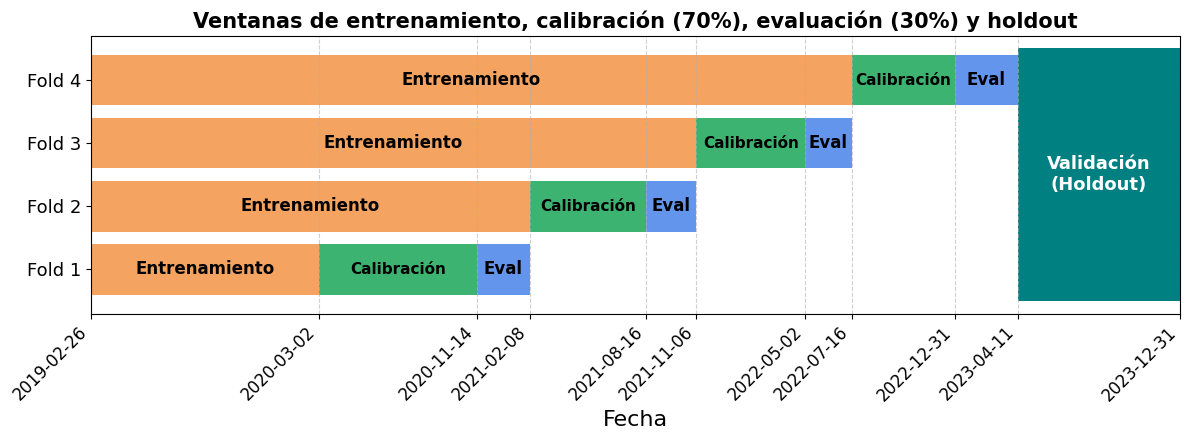

In [7]:
# Definir la CV interna de 4 splits sobre el dataset de entrenamiento/calibración (df_tr)
tscv_inner = TimeSeriesSplit(n_splits=4)
splits_inner = list(tscv_inner.split(df_tr))

plt.figure(figsize=(12, 4.5))

limites_temporales = set()

# Fechas de inicio y fin del holdout reservado
holdout_start = df_holdout['FECHA_FRANJA'].iloc[0]
holdout_end = df_holdout['FECHA_FRANJA'].iloc[-1]
width_holdout = holdout_end - holdout_start

for i, (train_idx, test_idx) in enumerate(splits_inner):
    # Calcular el índice de corte del 70% para calibración
    corte_idx = int(len(test_idx) * 0.7)
    
    # Fechas clave
    train_start = df_tr['FECHA_FRANJA'].iloc[train_idx[0]]
    corte_train_calib = df_tr['FECHA_FRANJA'].iloc[test_idx[0]]
    corte_calib_eval = df_tr['FECHA_FRANJA'].iloc[test_idx[corte_idx]]
    
    if i < len(splits_inner) - 1:
        test_end = df_tr['FECHA_FRANJA'].iloc[splits_inner[i+1][1][0]]
    else:
        test_end = df_tr['FECHA_FRANJA'].iloc[-1] 
        
    limites_temporales.update([train_start, corte_train_calib, corte_calib_eval, test_end])
    
    # Graficar entrenamiento (bloque naranja)
    width_train = corte_train_calib - train_start
    plt.barh(y=i+1, width=width_train, left=train_start, color="sandybrown")
    centro_x_train = train_start + (width_train / 2)
    plt.text(centro_x_train, i+1, "Entrenamiento", ha='center', va='center', 
             color='black', fontsize=12, fontweight='bold')
    
    # Graficar calibración 70% (bloque verde)
    width_calib = corte_calib_eval - corte_train_calib
    plt.barh(y=i+1, width=width_calib, left=corte_train_calib, color="mediumseagreen")
    centro_x_calib = corte_train_calib + (width_calib / 2)
    plt.text(centro_x_calib, i+1, "Calibración", ha='center', va='center', 
             color='black', fontsize=11, fontweight='bold')

    # Graficar evaluación OOF 30% (bloque azul)
    width_eval = test_end - corte_calib_eval
    plt.barh(y=i+1, width=width_eval, left=corte_calib_eval, color="cornflowerblue")
    centro_x_eval = corte_calib_eval + (width_eval / 2)
    plt.text(centro_x_eval, i+1, "Eval", ha='center', va='center', 
             color='black', fontsize=12, fontweight='bold')

# Graficar validación holdout
centro_y = (tscv_inner.n_splits + 1) / 2
altura_total = tscv_inner.n_splits

plt.barh(y=centro_y, width=width_holdout, left=holdout_start, 
         height=altura_total, color="teal")

# Texto centrado
centro_x_holdout = holdout_start + (width_holdout / 2)
plt.text(centro_x_holdout, centro_y, "Validación\n(Holdout)", ha='center', va='center', 
         color='white', fontsize=13, fontweight='bold')

# Agregar las fechas del holdout a las marcas del eje X
limites_temporales.update([holdout_start, holdout_end])

# Etiquetas eje Y
plt.yticks(range(1, tscv_inner.n_splits + 1), [f"Fold {i+1}" for i in range(tscv_inner.n_splits)], fontsize=13)

# Etiquetas eje X
fechas_ordenadas = sorted(limites_temporales)
etiquetas_fechas = [fecha.strftime("%Y-%m-%d") for fecha in fechas_ordenadas]

plt.xticks(fechas_ordenadas, etiquetas_fechas, rotation=45, ha="right", fontsize=12)
plt.xlabel("Fecha", fontdict={"size": 16})
plt.ylabel("", fontdict={"size": 16})
plt.xlim(fechas_ordenadas[0], fechas_ordenadas[-1])
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.title("Ventanas de entrenamiento, calibración (70%), evaluación (30%) y holdout", fontdict={"size": 15, "weight": "bold"})
plt.tight_layout() 
plt.show()

## 5. Selección de hiperparámetros

Se utilizó la métrica PR-AUC como criterio de evaluación para la búsqueda de hiperparámetros mediante 125 iteraciones por fold (500 estimaciones en total) utilizando Random Searcho (RS) con validación cruzada, ya que esta evalúa de manera más rigurosa la relación entre precisión y sensibilidad en este contexto de clases desbalanceadas.

In [8]:
actualizar = False # Cambia a True cuando quieras actualizar la búsqueda de hiperparámetros
archivo_config = 'config_modelo.json'

if actualizar or not os.path.exists(archivo_config):
    print("Iniciando búsqueda de hiperparámetros y calibración de umbral...")

    # Esquema de partición temporal (Walk-Forward)
    tscv = TimeSeriesSplit(n_splits=4)

    #  Espacio de búsqueda
    param_dist = {
        'n_estimators': [100, 200, 300, 400, 500, 600],
        'max_depth': [10, 15, 20, 25, 30, None],
        'min_samples_split': [5, 10, 15, 20, 50],
        'min_samples_leaf': [2, 4, 5, 10, 20],
        'max_features': ['sqrt', 'log2', None, 0.5, 0.7, 1.0],
        'class_weight': ['balanced', 'balanced_subsample', None, {0:1, 1:5}],
        'criterion': ['gini', 'entropy', 'log_loss'],
        'max_samples': [0.5, 0.7, 0.9, 1.0]
    }

    # Modelo base
    rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

    # Configurar la Búsqueda Aleatoria
    # Usamos PR-AUC ('average_precision'), por le desbalance de clases.
    random_search = RandomizedSearchCV(
        estimator=rf_base,
        param_distributions=param_dist,
        n_iter=125,               # Número de combinaciones a probar
        scoring='average_precision', 
        cv=tscv,                 # Validador temporal
        random_state=42,
        n_jobs=-1,               # Usa todos los núcleos disponibles
        verbose=2
    )

    # Ejecutar la búsqueda
    print("Iniciando búsqueda de hiperparámetros...")
    random_search.fit(X_tr, y_tr)
    
    # Guardar los nuevos valores en el JSON
    nueva_config = {
        "hiperparametros": random_search.best_params_,
        "PR-AUC": round(random_search.best_score_, 4)
    }
    with open(archivo_config, 'w') as f:
        json.dump(nueva_config, f, indent=4)
    print("Nuevos parámetros guardados en JSON.")

    best_hypers = random_search.best_params_
    PR_AUC = round(random_search.best_score_, 4)

else:
    # Cargar valores instantáneamente
    with open(archivo_config, 'r') as f:
        config = json.load(f)
    
    best_hypers = config["hiperparametros"]
    PR_AUC = config["PR-AUC"]
    print("Cargando parámetros desde JSON. Entrenamiento omitido.")
    # Mostrar los mejores hiperparámetros encontrados
print("\nMejores hiperparámetros encontrados:")
print(best_hypers)
print(f"Mejor PR-AUC en validación cruzada: {PR_AUC}")

Cargando parámetros desde JSON. Entrenamiento omitido.

Mejores hiperparámetros encontrados:
{'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 20, 'max_samples': 1.0, 'max_features': 'log2', 'max_depth': 25, 'criterion': 'log_loss', 'class_weight': None}
Mejor PR-AUC en validación cruzada: 0.3046


## 6. Validación de modelos

La obtención del umbral de clasificación óptimo se obtiene mediante los conjuntos de evaluacion OOF. La validación del modelo RF y del proceso de calibración aplicado se basó en métricas obtenidas exclusivamente a partir del conjunto holdout, con el fin de evitar sobreajuste.

### 6.1 Ensamble y calibración

En trabajos de seguridad vial, es importante calibrar los modelos para que los mapas de riesgo se apeguen lo más posible a la realidad, evitando sobreestimaciones o subestimaciones del riesgo. Intentando corregir este sesgo, se aplicó la Regresión Isotónica, la cual es un método de calibración *post hoc* no paramétrico que ajusta las probabilidades crudas a una función monótona no decreciente.

In [9]:
# Cambia a True SOLO cuando quieras volver a entrenar el modelo desde cero
actualizar_modelo = False 
archivo_modelo = 'modelo_evaluacion.pkl'

if actualizar_modelo or not os.path.exists(archivo_modelo):
    print("Entrenando Modelo Calibrado...")
    
    # Configuración inicial
    tscv = TimeSeriesSplit(n_splits=4)
    rf_interno = RandomForestClassifier(**best_hypers, random_state=42, n_jobs=-1)
    modelo_calibrado = CalibratedClassifierCV(estimator=rf_interno, method='isotonic', cv=tscv)
    modelo_calibrado.fit(X_tr, y_tr)
    
    # Guardar el modelo recién entrenado
    joblib.dump(modelo_calibrado, archivo_modelo)
    print("Modelo Calibrado entrenado y guardado")
else:
    # Cargar el modelo
    print("Cargando Modelo Calibrado. Entrenamiento omitido...")
    modelo_calibrado = joblib.load(archivo_modelo)
    print("Modelo cargado exitosamente.")

print("Extrayendo Ensamble Base...")
class EnsambleBaseOOF:
    """Extrae los Random Forest crudos del calibrador para promediar sus probabilidades puras."""
    def __init__(self, calibrador_entrenado):
        # Extraemos los estimadores base que ya fueron entrenados en los pliegues temporales
        self.modelos_base = [
            calibrado.estimator for calibrado in calibrador_entrenado.calibrated_classifiers_
        ]    

    def predict_proba(self, X):
        # Promedia las predicciones crudas de los modelos
        preds = [modelo.predict_proba(X) for modelo in self.modelos_base]
        return np.mean(preds, axis=0)

modelo_base = EnsambleBaseOOF(modelo_calibrado)

print("Modelo Base obtenido y listo para hacer predicciones.")

Cargando Modelo Calibrado. Entrenamiento omitido...


Modelo cargado exitosamente.
Extrayendo Ensamble Base...
Modelo Base obtenido y listo para hacer predicciones.


### 6.2 Umbrales óptimos de clasificación

Se realizó un ajuste de umbral de clasificación $\tau$ sobre los conjuntos de evaluación, debido a que el umbral estándar de 0.5, no refleja el punto de equilibrio entre la precisión y sensibilidad en este contexto de clases desbalanceadas. En este caso, se utilizó la curva Precisión-Sensibilidad sobre las predicciones de todos los pliegues de evaluación, seleccionando aquel punto que maximice el valor F1.

In [10]:
def optimizar_umbral_f1(y_true: np.ndarray, y_prob: np.ndarray, tipo_modelo: str = None) -> tuple:
    """
    Calcula el umbral óptimo maximizando el F1-Score sobre la curva Precisión-Sensibilidad (PR) y visualiza las métricas.

    Parámetros
    ----------
    `y_true` : np.ndarray
        Etiquetas reales de clasificación binaria (valores 0 y 1) del conjunto de validación o prueba (OOF).

    `y_prob` : np.ndarray
        Probabilidades predichas por el modelo para la clase positiva (valores entre 0.0 y 1.0).

    `tipo_modelo` : str, opcional
        Cadena de texto con el nombre o estado del modelo (ej. 'base', 'calibrado') 
        que se utilizará para personalizar el título del gráfico generado.

    Retorna
    -------
    `umbral_optimo` : float
        El umbral de probabilidad exacto en el cual se maximiza la métrica F1-Score.
        
    `f1_optimo` : float
        El valor del F1-Score máximo alcanzado al utilizar el umbral óptimo.
    """
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    f1 = 2 * (precision * recall) / (precision + recall + np.finfo(float).eps)
    
    if len(thresholds) == 0:
        return 0.5, f1.max()
        
    best_idx = np.nanargmax(f1[:-1])

    umbral_optimo, f1_optimo = thresholds[best_idx], f1[best_idx]

    plt.subplots(figsize=(12, 6))

    if len(thresholds) > 0:
        plt.plot(thresholds, precision[:-1], 'b--', label='Precisión')
        plt.plot(thresholds, recall[:-1], 'g--', label='Sensibilidad')
        plt.plot(thresholds, f1[:-1], 'r-', label='F1')

        # Línea vertical y punto destacado en el umbral óptimo
        plt.axvline(x=umbral_optimo, color='k', linestyle=':', label='Umbral F1 máx')
        plt.scatter(umbral_optimo, f1_optimo, color='red', s=80, zorder=5, label='F1 óptimo')
        
        # Texto con el valor
        plt.text(umbral_optimo + 0.035, f1_optimo + 0.02, 
                 f"Umbral={umbral_optimo:.4f}\nF1={f1_optimo:.4f}", 
                 ha='center', va='bottom', fontsize=12, color='red')
        
        plt.xlabel('Umbral de probabilidad', fontdict={"size":15})
        plt.ylabel('Puntaje', fontdict={"size":15})
        plt.xticks(fontsize = 14)
        plt.yticks(fontsize = 14)
        plt.title(f'Evaluación de métricas OOF según umbral de probabilidad (Modelo {tipo_modelo})', 
                  fontdict={"size":17, "weight":"bold"})
        plt.legend(fontsize=13)
        plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    return umbral_optimo, f1_optimo

Iniciando cálculo y calibración del umbral OOF...


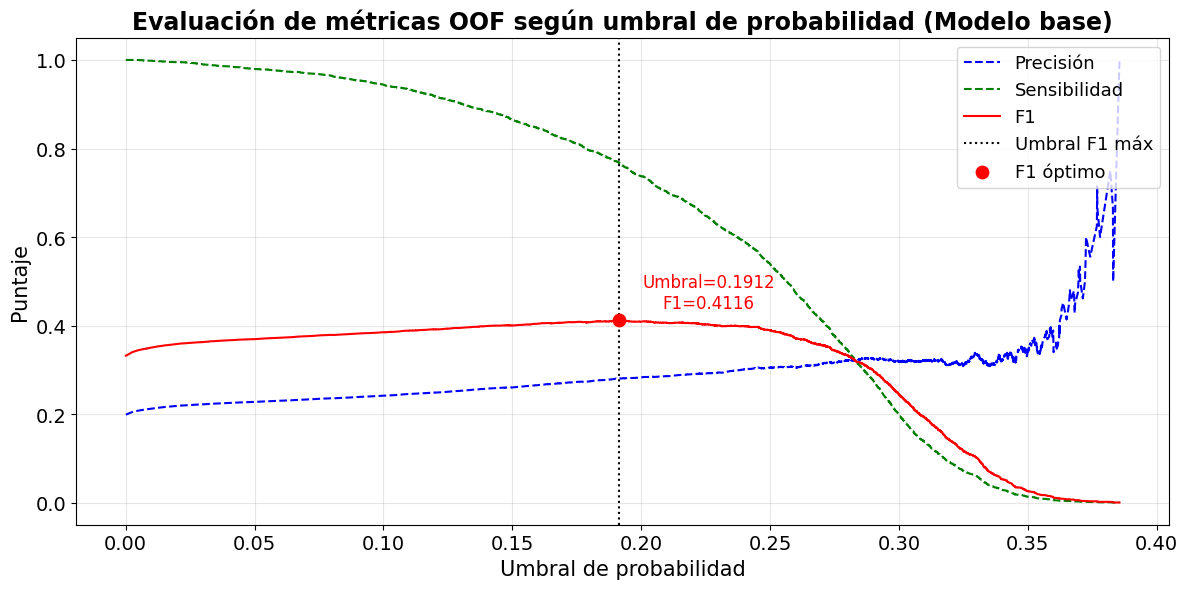

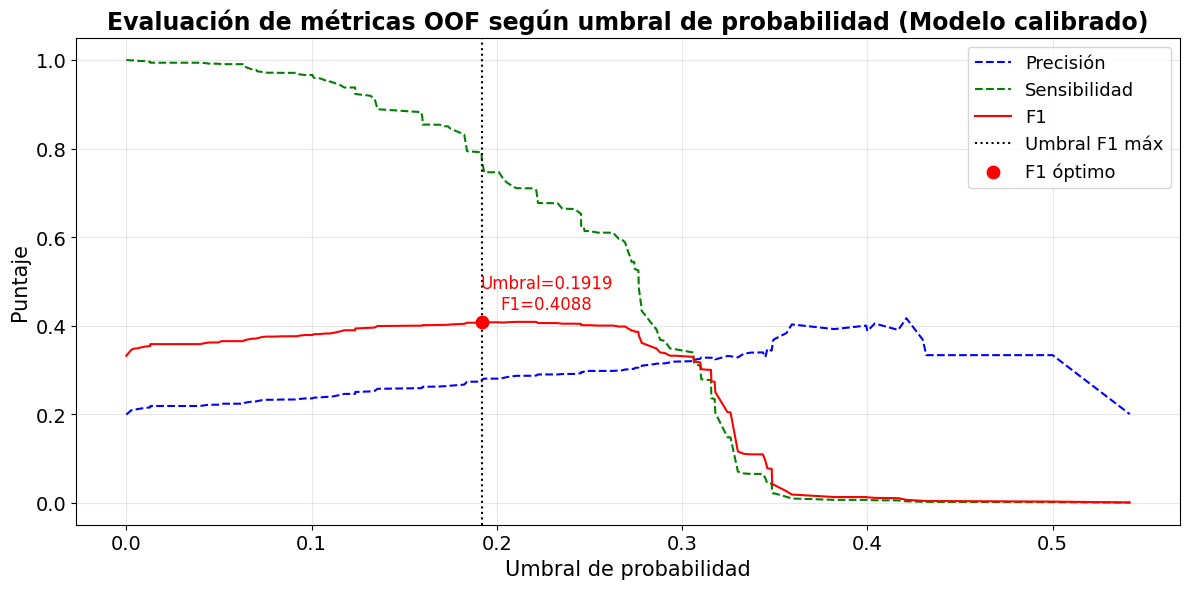

Umbral calibrado guardado en JSON.
--- UMBRALES ÓPTIMOS (OOF) ---
Modelo Base      -> Umbral: 0.19123509865256674 | F1: 0.4116
Modelo Calibrado -> Umbral: 0.19187358916478556 | F1: 0.4088


In [ ]:
actualizar = False  # Cambia a True si quieres recalibrar el umbral
archivo_umbral = 'umbral_config.json'

if actualizar or not os.path.exists(archivo_umbral):
    print("Iniciando cálculo y calibración del umbral OOF...")
    
    frac_calib = 0.7  # proporción del bloque de calibración

    oof_y_true_v2 = []
    oof_prob_base_v2 = []
    oof_prob_calibrado_v2 = []

    tscv = TimeSeriesSplit(n_splits=4)
    splits = list(tscv.split(X_tr))

    for i, (train_idx, val_idx) in enumerate(splits):
        corte = int(len(val_idx) * frac_calib)
        calib_idx = val_idx[:corte]   # Ajusta el calibrador
        test_idx  = val_idx[corte:]   # Evaluación OOF

        X_train_fold, y_train_fold = X_tr.iloc[train_idx], y_tr.iloc[train_idx]
        X_calib, y_calib = X_tr.iloc[calib_idx], y_tr.iloc[calib_idx]
        X_test, y_test   = X_tr.iloc[test_idx],  y_tr.iloc[test_idx]

        # RF entrenado solo con el conjunto de entrenamiento
        rf_fold = RandomForestClassifier(**best_hypers, random_state=42, n_jobs=-1)
        rf_fold.fit(X_train_fold, y_train_fold)

        # Calibrador solo con el conjunto de calibración
        prob_calib_raw = rf_fold.predict_proba(X_calib)[:, 1]
        iso = IsotonicRegression(out_of_bounds='nan')
        iso.fit(prob_calib_raw, y_calib)

        # Evaluación solo con el conjunto de validación (OOF)
        prob_test_raw = rf_fold.predict_proba(X_test)[:, 1]
        prob_test_cal = iso.transform(prob_test_raw)

        oof_y_true_v2.extend(y_test)
        oof_prob_base_v2.extend(prob_test_raw)
        oof_prob_calibrado_v2.extend(prob_test_cal)

    oof_y_true_v2 = np.array(oof_y_true_v2)
    oof_prob_base_v2 = np.array(oof_prob_base_v2)
    oof_prob_calibrado_v2 = np.array(oof_prob_calibrado_v2)

    # Crear una máscara que identifique qué predicciones no son nulas
    mask_validos = ~np.isnan(oof_prob_calibrado_v2)

    # Filtrar las etiquetas reales y las predicciones calibradas usando la máscara
    y_true_validos = oof_y_true_v2[mask_validos]
    prob_cal_validos = oof_prob_calibrado_v2[mask_validos]

    umbral_base, f1_base_v2 = optimizar_umbral_f1(oof_y_true_v2, oof_prob_base_v2, "base")
    umbral_calibrado, f1_cal_v2 = optimizar_umbral_f1(y_true_validos, prob_cal_validos, "calibrado")

    # Guardar el umbral calculado
    config_umbral = {
        "umbral_base": umbral_base,
        "umbral_calibrado": umbral_calibrado,
        "F1_base": round(f1_base_v2, 4),
        "F1_calibrado": round(f1_cal_v2, 4)
    }
    
    with open(archivo_umbral, 'w') as f:
        json.dump(config_umbral, f, indent=4)
    print("Umbral calibrado guardado en JSON.")

else:
    # Cargar el umbral instantáneamente
    with open(archivo_umbral, 'r') as f:
        config_umbral = json.load(f)
        
    umbral_base, f1_base_v2 = config_umbral["umbral_base"], config_umbral["F1_base"]
    umbral_calibrado, f1_cal_v2 = config_umbral["umbral_calibrado"], config_umbral["F1_calibrado"]
    print("Cargando umbral desde JSON. Cálculo omitido.")

print("--- UMBRALES ÓPTIMOS (OOF) ---")
print(f"Modelo Base      -> Umbral: {umbral_base} | F1: {f1_base_v2:.4f}")
print(f"Modelo Calibrado -> Umbral: {umbral_calibrado} | F1: {f1_cal_v2:.4f}")

### 6.3 Métricas de rendimeinto general

Para evaluar el nivel de calibración del modelo de RF y del proceso de calibración aplicado, se utilizaron métricas obtenidas exclusivamente a partir del conjunto holdout, con el fin de evitar sobreajuste.

=== MATRIZ DE CONFUSIÓN HOLDOUT (BASE) ===


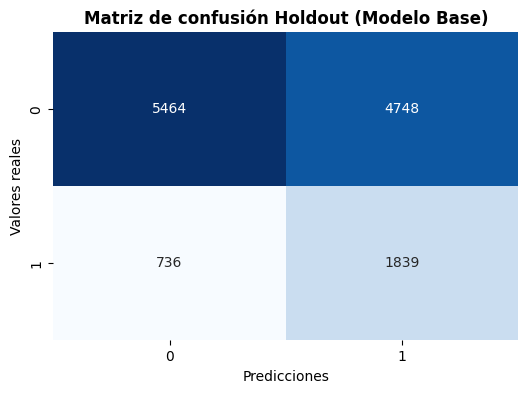


=== REPORTE DE CLASIFICACIÓN HOLDOUT (BASE) ===
              precision    recall  f1-score   support

           0     0.8813    0.5351    0.6659     10212
           1     0.2792    0.7142    0.4014      2575

    accuracy                         0.5711     12787
   macro avg     0.5802    0.6246    0.5336     12787
weighted avg     0.7600    0.5711    0.6126     12787


=== MATRIZ DE CONFUSIÓN HOLDOUT (CALIBRADO) ===


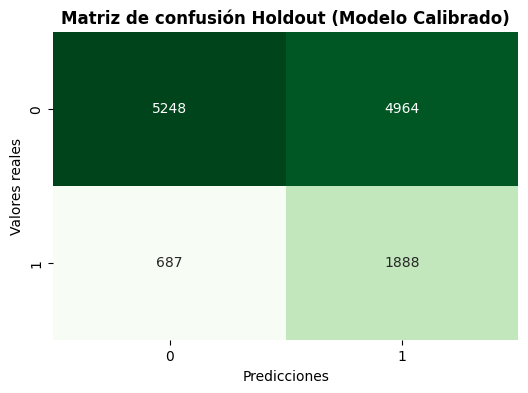


=== REPORTE DE CLASIFICACIÓN HOLDOUT (CALIBRADO) ===
              precision    recall  f1-score   support

           0     0.8842    0.5139    0.6500     10212
           1     0.2755    0.7332    0.4006      2575

    accuracy                         0.5581     12787
   macro avg     0.5799    0.6236    0.5253     12787
weighted avg     0.7617    0.5581    0.5998     12787



In [12]:
# 1. Generar probabilidades puras sobre el HOLDOUT (Examen ciego)
prob_base_holdout = modelo_base.predict_proba(X_holdout)[:, 1]
prob_calibrado_holdout = modelo_calibrado.predict_proba(X_holdout)[:, 1]

# 2. Aplicar los umbrales matemáticos congelados (aprendidos en Entrenamiento)
preds_base_holdout = (prob_base_holdout >= umbral_base).astype(int)
preds_calibrado_holdout = (prob_calibrado_holdout >= umbral_calibrado).astype(int)

# ==========================================
# EVALUACIÓN: MODELO BASE
# ==========================================
print("=== MATRIZ DE CONFUSIÓN HOLDOUT (BASE) ===")
cm_base = confusion_matrix(y_holdout, preds_base_holdout)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_base, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicciones")
plt.ylabel("Valores reales")
plt.title("Matriz de confusión Holdout (Modelo Base)", fontweight="bold")
plt.show()

print("\n=== REPORTE DE CLASIFICACIÓN HOLDOUT (BASE) ===")
print(classification_report(y_holdout, preds_base_holdout, digits=4))

# ==========================================
# EVALUACIÓN: MODELO CALIBRADO
# ==========================================
print("\n=== MATRIZ DE CONFUSIÓN HOLDOUT (CALIBRADO) ===")
cm_calibrado = confusion_matrix(y_holdout, preds_calibrado_holdout)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_calibrado, annot=True, fmt="d", cmap="Greens", cbar=False) # Verde para diferenciar visualmente
plt.xlabel("Predicciones")
plt.ylabel("Valores reales")
plt.title("Matriz de confusión Holdout (Modelo Calibrado)", fontweight="bold")
plt.show()

print("\n=== REPORTE DE CLASIFICACIÓN HOLDOUT (CALIBRADO) ===")
print(classification_report(y_holdout, preds_calibrado_holdout, digits=4))

### 6.4 Métricas de calibración

En este análisis se reportan dos métricas de calibración: BS para evaluación global y ECE para contraste local dividiendo las probabilidades en 15 cuantiles.

=== EVALUACIÓN DE CALIBRACIÓN (BRIER SCORE) ===
Brier Score Base:      0.1521
Brier Score Calibrado: 0.1518
Mejora en el error:    0.20%



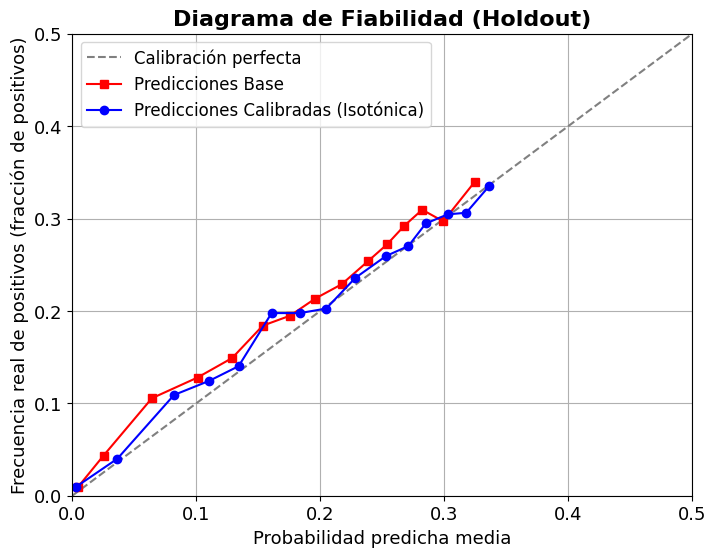

Modelo Base (Holdout):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
prob_pred_base,0.004553,0.025211,0.064201,0.101025,0.128961,0.153611,0.175635,0.195932,0.217274,0.238220,0.253796,0.267832,0.282184,0.299184,0.324717
prob_true_base,0.009379,0.043427,0.105510,0.127934,0.149061,0.184056,0.194836,0.213365,0.228873,0.253521,0.271981,0.292254,0.309496,0.296948,0.339977



Modelo Calibrado (Holdout):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
prob_pred_cal,0.002741,0.036398,0.082050,0.110579,0.134152,0.160761,0.183565,0.204789,0.228233,0.252912,0.271055,0.285057,0.302641,0.317694,0.336418
prob_true_cal,0.009335,0.040094,0.109027,0.124413,0.140230,0.197661,0.197661,0.202576,0.235714,0.259346,0.270238,0.294624,0.304459,0.306257,0.335467


In [13]:
# Comparación del Brier Score en el holdout
brier_base = brier_score_loss(y_holdout, prob_base_holdout)
brier_cal = brier_score_loss(y_holdout, prob_calibrado_holdout)
mejora_pct = ((brier_base - brier_cal) / brier_base) * 100

print("=== EVALUACIÓN DE CALIBRACIÓN (BRIER SCORE) ===")
print(f"Brier Score Base:      {brier_base:.4f}")
print(f"Brier Score Calibrado: {brier_cal:.4f}")
print(f"Mejora en el error:    {mejora_pct:.2f}%\n")

# Calcular las curvas de calibración (frecuencia de positivos vs. probabilidad media) en el holdout
prob_true_base, prob_pred_base = calibration_curve(y_holdout, prob_base_holdout, n_bins=15, strategy='quantile')
prob_true_cal, prob_pred_cal = calibration_curve(y_holdout, prob_calibrado_holdout, n_bins=15, strategy='quantile')

# Gráfico 
plt.figure(figsize=(8, 6))
# Línea de calibración perfecta (la diagonal)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración perfecta')
# Curva del modelo base
plt.plot(prob_pred_base, prob_true_base, marker='s', color='red', label='Predicciones Base')
# Curva del modelo calibrado
plt.plot(prob_pred_cal, prob_true_cal, marker='o', color='blue', label='Predicciones Calibradas (Isotónica)')

# Personalización del gráfico
plt.xlabel('Probabilidad predicha media', fontdict={"size":13})
plt.ylabel('Frecuencia real de positivos (fracción de positivos)', fontdict={"size":13})
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.xlim(0, 0.5)
plt.ylim(0, 0.5)
plt.title('Diagrama de Fiabilidad (Holdout)', fontdict={"size":16, "weight":"bold"})
plt.legend(loc='upper left', fontsize=12)
plt.grid(True)
plt.show()

# DataFrame para el modelo base
df_base = pd.DataFrame({
    "prob_pred_base": prob_pred_base,
    "prob_true_base": prob_true_base
})

# DataFrame para el modelo calibrado
df_cal = pd.DataFrame({
    "prob_pred_cal": prob_pred_cal,
    "prob_true_cal": prob_true_cal
})

print("Modelo Base (Holdout):")
display(df_base.T)

print("\nModelo Calibrado (Holdout):")
display(df_cal.T)

In [14]:
# Comparación del Error de Calibración Esperado (ECE)
def expected_calibration_error(y_true, y_prob, n_bins=10, strategy='uniform'):
    """
    Calcula el Expected Calibration Error (ECE) de un clasificador probabilístico.

    Parameters
    ----------
    y_true : array-like
        Etiquetas reales (0/1).
    y_prob : array-like
        Probabilidades predichas de la clase positiva.
    n_bins : int, default=10
        Número de bins a utilizar.
    strategy : {'uniform', 'quantile'}, default='uniform'
        'uniform'  -> bins de igual ancho en [0, 1] (definición clásica, Guo et al. 2017).
        'quantile' -> bins con igual número de observaciones (útil si las probabilidades
                      están muy concentradas y los bins uniformes quedan vacíos; es
                      consistente con el 'strategy' usado en calibration_curve más abajo).

    Returns
    -------
    ece : float
        Expected Calibration Error (0 = calibración perfecta).
    bin_info : pd.DataFrame
        Detalle por bin: rango, número de muestras, confianza media, precisión real
        y la brecha absoluta entre ambas.
    """
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    n = len(y_true)

    if strategy == 'uniform':
        bin_edges = np.linspace(0, 1, n_bins + 1)
    elif strategy == 'quantile':
        bin_edges = np.unique(np.quantile(y_prob, np.linspace(0, 1, n_bins + 1)))
        bin_edges[0], bin_edges[-1] = 0.0, 1.0
    else:
        raise ValueError("strategy debe ser 'uniform' o 'quantile'")

    ece = 0.0
    registros = []

    for i in range(len(bin_edges) - 1):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        es_ultimo_bin = (i == len(bin_edges) - 2)
        mask = (y_prob >= lo) & (y_prob <= hi) if es_ultimo_bin else (y_prob >= lo) & (y_prob < hi)

        n_bin = mask.sum()
        if n_bin == 0:
            continue

        conf_bin = y_prob[mask].mean()   # probabilidad media predicha (confianza)
        acc_bin = y_true[mask].mean()    # fracción real de positivos (precisión real)
        gap = abs(acc_bin - conf_bin)

        ece += (n_bin / n) * gap

        registros.append({
            "bin": f"[{lo:.2f}, {hi:.2f}]",
            "n_muestras": int(n_bin),
            "confianza_media": conf_bin,
            "precision_real": acc_bin,
            "brecha_abs": gap
        })

    bin_info = pd.DataFrame(registros)
    return ece, bin_info

# Cálculo del ECE para el modelo base y el calibrado (15 bins por cuantiles) en el holdout
ece_base, bins_base = expected_calibration_error(y_holdout, prob_base_holdout, n_bins=15, strategy='quantile')
ece_cal, bins_cal = expected_calibration_error(y_holdout, prob_calibrado_holdout, n_bins=15, strategy='quantile')

mejora_ece_pct = ((ece_base - ece_cal) / ece_base) * 100

print("=== EVALUACIÓN DE CALIBRACIÓN (ECE) EN HOLDOUT ===")
print(f"ECE Base:         {ece_base:.4f}")
print(f"ECE Calibrado:    {ece_cal:.4f}")
print(f"Mejora en el ECE: {mejora_ece_pct:.2f}%\n")

print("Detalle por bin - Modelo Base (Holdout):")
display(bins_base)

print("\nDetalle por bin - Modelo Calibrado (Holdout):")
display(bins_cal)

=== EVALUACIÓN DE CALIBRACIÓN (ECE) EN HOLDOUT ===
ECE Base:         0.0195
ECE Calibrado:    0.0099
Mejora en el ECE: 49.13%

Detalle por bin - Modelo Base (Holdout):


,bin,n_muestras,confianza_media,precision_real,brecha_abs
0,"[0.00, 0.01]",853,0.004553,0.009379,0.004826
1,"[0.01, 0.04]",852,0.025211,0.043427,0.018216
2,"[0.04, 0.08]",853,0.064201,0.105510,0.041309
3,"[0.08, 0.12]",852,0.101025,0.127934,0.026909
4,"[0.12, 0.14]",852,0.128961,0.149061,0.020100
5,"[0.14, 0.16]",853,0.153611,0.184056,0.030445
6,"[0.16, 0.19]",852,0.175635,0.194836,0.019201
7,"[0.19, 0.21]",853,0.195932,0.213365,0.017432
8,"[0.21, 0.23]",852,0.217274,0.228873,0.011599
9,"[0.23, 0.25]",852,0.238220,0.253521,0.015302



Detalle por bin - Modelo Calibrado (Holdout):


,bin,n_muestras,confianza_media,precision_real,brecha_abs
0,"[0.00, 0.01]",849,0.002660,0.009423,0.006763
1,"[0.01, 0.06]",856,0.036163,0.039720,0.003556
2,"[0.06, 0.10]",853,0.082050,0.109027,0.026977
3,"[0.10, 0.12]",852,0.110579,0.124413,0.013834
4,"[0.12, 0.15]",815,0.133242,0.139877,0.006635
5,"[0.15, 0.17]",887,0.159592,0.192785,0.033193
6,"[0.17, 0.19]",828,0.182791,0.194444,0.011653
7,"[0.19, 0.22]",855,0.203357,0.208187,0.004830
8,"[0.22, 0.24]",871,0.227358,0.229621,0.002263
9,"[0.24, 0.26]",839,0.252232,0.259833,0.007602


## 7. Análisis de importancia SHAP

Para garantizar que los valores SHAP sean representativos y no estén sobreajustados, se aplica el análisis de importancia sobre el conjunto *holdout*. El esquema metodológico de explicabilidad se estructuró en tres niveles complementarios de evaluación: análisis de importancia agregada por bloques de variables, impacto global y direccionalidad individual, y comparación entre valores SHAP y MDI.

In [15]:
# Diccionario de Nombres de Variables
nombres_vars = {
    "DIST_NODO_5_MAS": "Dist. a nodo grado ≥5",
    "CAMINO": "Camino",
    "DIST_MAN_PROH": "Dist. a maniobra prohibida",
    "DIST_NODO_4": "Dist. a nodo grado 4",
    "WIND_SPEED_MEAN_PREV": "Velocidad viento previa",
    "SOIL_MOISTURE_MEAN_PREV": "Humedad suelo previa",
    "CLOUD_COVER_MEAN_PREV": "Cobertura nubes previa",
    "WIND_GUSTS_MAX_PREV": "Rachas viento previas",
    "SOIL_TEMP_MEAN_PREV": "Temp. suelo previa",
    "APP_TEMP_MEAN_PREV": "Temp. aparente previa",
    "TEMP_MEAN_PREV": "Temp. media previa",
    "TEMP_MIN_PREV": "Temp. mínima previa",
    "DIST_NODO_3": "Dist. a nodo grado 3",
    "LONGITUD": "Longitud",
    "SINUOSIDAD": "Sinuosidad",
    "VELOCIDAD": "Velocidad",
    "DELTA_VELOCIDAD_MEAN": "Cambio medio velocidad",
    "AVENIDA": "Avenida",
    "DELTA_CARRILES_MEAN": "Cambio medio carriles",
    "GRADO_MIN": "Grado mínimo nodo",
    "GRADO_MAX": "Grado máximo nodo",
    "UN_SENTIDO": "Un sentido",
    "DIASEMANA_SIN": "Seno día semana",
    "MES_SIN": "Seno mes",
    "MES_COS": "Coseno mes",
    "CARRILES": "Número de carriles",
    "DELTA_VELOCIDAD_MAX": "Cambio máximo velocidad",
    "ACC_LOCAL_2M": "Accidentes 2 meses",
    "PRECIP_SUM_PREV": "Precipitación acumulada previa",
    "PANDEMIA": "Pandemia",
    "PRECIP_MAX_PREV": "Precipitación máxima previa",
    "DIASEMANA_COS": "Coseno día semana",
    "BOULEVARD": "Boulevard",
    "DELTA_CARRILES_MAX": "Cambio máximo carriles",
    "FRANJA_COS": "Coseno franja horaria",
    "CIRCUITO": "Circuito",
    "VACACIONES": "Vacaciones",
    "DOS_SENTIDOS": "Dos sentidos",
    "ACC_LOCAL_2W": "Accidentes 2 semanas",
    "FRANJA_SIN": "Seno franja horaria",
    "ACC_LOCAL_1M": "Accidentes 1 mes",
    "CARRETERA": "Carretera",
    "PRIVADA": "Privada",
    "CALLE": "Calle",
    "FESTIVO": "Festivo",
    "DELTA_VELOCIDAD_MIN": "Cambio mínimo velocidad",
    "PROMOCION": "Promociones departamentales",
    "MENOR": "Vía menor",
    "NIVEL": "Nivel",
    "DELTA_CARRILES_MIN": "Cambio mínimo carriles",
    "CERRADA_EN_AMBOS_SENTIDOS": "Cerrada ambos sentidos",
    "RETORNO_U": "Retorno en U",
    "INCORPORACION": "Incorporación",
    "FNSM": "Evento FNSM",
    "GLORIETA": "Glorieta"
}

# FUNCIÓN PARA TRADUCCIÓN DE ETIQUETA
def traducir_etiquetas_shap(ax: plt.Axes) -> None:
    """
    Traduce etiquetas generadas por SHAP en un gráfico de Matplotlib. SHAP genera etiquetas en inglés con el formato:
        "Sum of N other features"
    donde N es el número de variables agrupadas.

    Esta función reemplaza dichas etiquetas por su equivalente en español:
        "Suma de otras N variables"

    Parámetros
    ----------
    ax: Objeto de eje actual en Matplotlib 
        sobre el cual se aplicará la traducción.

    Retorna
    -------
    None
        La función modifica directamente las etiquetas del eje proporcionado.
    """
    # Extraer los textos de las etiquetas actuales del eje Y
    etiquetas = [item.get_text() for item in ax.get_yticklabels()]
    nuevas_etiquetas = []
    
    for texto in etiquetas:
        if "Sum of" in texto and "other features" in texto:
            # El formato de SHAP es "Sum of 34 other features"
            # Dividimos el texto y extraemos el número (índice 2)
            cantidad = texto.split()[2] 
            nuevas_etiquetas.append(f"Suma de otras {cantidad} variables")
        else:
            nuevas_etiquetas.append(texto)
            
    # Asignar las nuevas etiquetas al gráfico
    ax.set_yticks(ax.get_yticks())
    ax.set_yticklabels(nuevas_etiquetas)

In [16]:
# Configuración de guardado
actualizar_shap = False  # Cambia a True cuando necesites recalcular
ruta_archivo_shap = "shap_datos_holdout.joblib"

if actualizar_shap or not os.path.exists(ruta_archivo_shap):
    print("Iniciando cálculo de valores SHAP (esto puede tomar tiempo)...")
    
    # Definir el tamaño de la muestra sobre el holdout
    n_muestra = 3000  

    sss = StratifiedShuffleSplit(n_splits=1, test_size=n_muestra, random_state=42)
    _, idx_muestra = next(sss.split(X_holdout, y_holdout))

    X_shap_holdout = X_holdout.iloc[idx_muestra].reset_index(drop=True)
    y_shap_holdout = y_holdout.iloc[idx_muestra].reset_index(drop=True)

    # Renombre de variables para gráficos SHAP
    if 'nombres_vars' in locals():
        X_shap_holdout = X_shap_holdout.rename(columns=nombres_vars)

    print(f"Muestra para SHAP (Holdout): {len(X_shap_holdout):,} filas")
    print(f"  Clase 0 (sin accidente): {(y_shap_holdout==0).sum():,} ({(y_shap_holdout==0).mean()*100:.1f}%)")
    print(f"  Clase 1 (con accidente): {(y_shap_holdout==1).sum():,} ({(y_shap_holdout==1).mean()*100:.1f}%)")
    print(f"  Variables: {X_shap_holdout.shape[1]}")

    # CÁLCULO SHAP DEL MODELO BASE PROMEDIADO
    shap_values_list = []
    expected_values_list = []
    importances_list = []

    n_modelos = len(modelo_base.modelos_base)
    print(f"\nCalculando valores SHAP para el ensamble base ({n_modelos} modelos)...")

    for i, modelo in enumerate(modelo_base.modelos_base):
        print(f"    Procesando Modelo {i+1}/{n_modelos}")
        
        # Inicializar explainer
        explainer = shap.TreeExplainer(
            modelo, 
            feature_perturbation='tree_path_dependent'
        )
        
        # Calcular valores SHAP
        shap_values_obj = explainer(X_shap_holdout)
        
        # Valores de clase 1 (probabilidad de accidente)
        shap_vals_clase1 = shap_values_obj.values[:, :, 1]
        shap_values_list.append(shap_vals_clase1)
        
        # Guardado de expected value de clase 1
        expected_values_list.append(explainer.expected_value[1])
        
        # Guardado de importancia
        importances_list.append(modelo.feature_importances_)
        
        print(f"    Modelo {i+1}/{n_modelos} procesado.")

    # Promediar todo a través de los modelos del ensamble
    shap_vals_promedio = np.mean(shap_values_list, axis=0)
    expected_value_promedio = np.mean(expected_values_list)
    importance_promedio = np.mean(importances_list, axis=0)

    # Guardar los datos en disco
    datos_shap_guardar = {
        "X_shap_holdout": X_shap_holdout,
        "y_shap_holdout": y_shap_holdout,
        "shap_vals_promedio": shap_vals_promedio,
        "expected_value_promedio": expected_value_promedio,
        "importance_promedio": importance_promedio
    }
    
    joblib.dump(datos_shap_guardar, ruta_archivo_shap)
    print(f"\nValores SHAP calculados y guardados en {ruta_archivo_shap}")

else:
    # Cargar los datos SHAP previamente calculados
    print(f"Cargando valores SHAP previamente calculados desde {ruta_archivo_shap}...")
    datos_cargados = joblib.load(ruta_archivo_shap)
    
    # Extraer variables
    X_shap_holdout = datos_cargados["X_shap_holdout"]
    y_shap_holdout = datos_cargados["y_shap_holdout"]
    shap_vals_promedio = datos_cargados["shap_vals_promedio"]
    expected_value_promedio = datos_cargados["expected_value_promedio"]
    importance_promedio = datos_cargados["importance_promedio"]
    
    print("Datos cargados")

print(f"\nValor base promedio (clase 1): {expected_value_promedio:.4f}")
print(f"Rango de valores SHAP: [{shap_vals_promedio.min():.4f}, {shap_vals_promedio.max():.4f}]")

# Objeto explanation SHAP para gráficos y análisis posterior
shap_explanation_holdout = shap.Explanation(
    values=shap_vals_promedio,
    base_values=np.full(len(X_shap_holdout), expected_value_promedio),
    data=X_shap_holdout.values,
    feature_names=X_shap_holdout.columns.tolist()
)

Cargando valores SHAP previamente calculados desde shap_datos_holdout.joblib...
Datos cargados

Valor base promedio (clase 1): 0.2000
Rango de valores SHAP: [-0.0823, 0.0481]


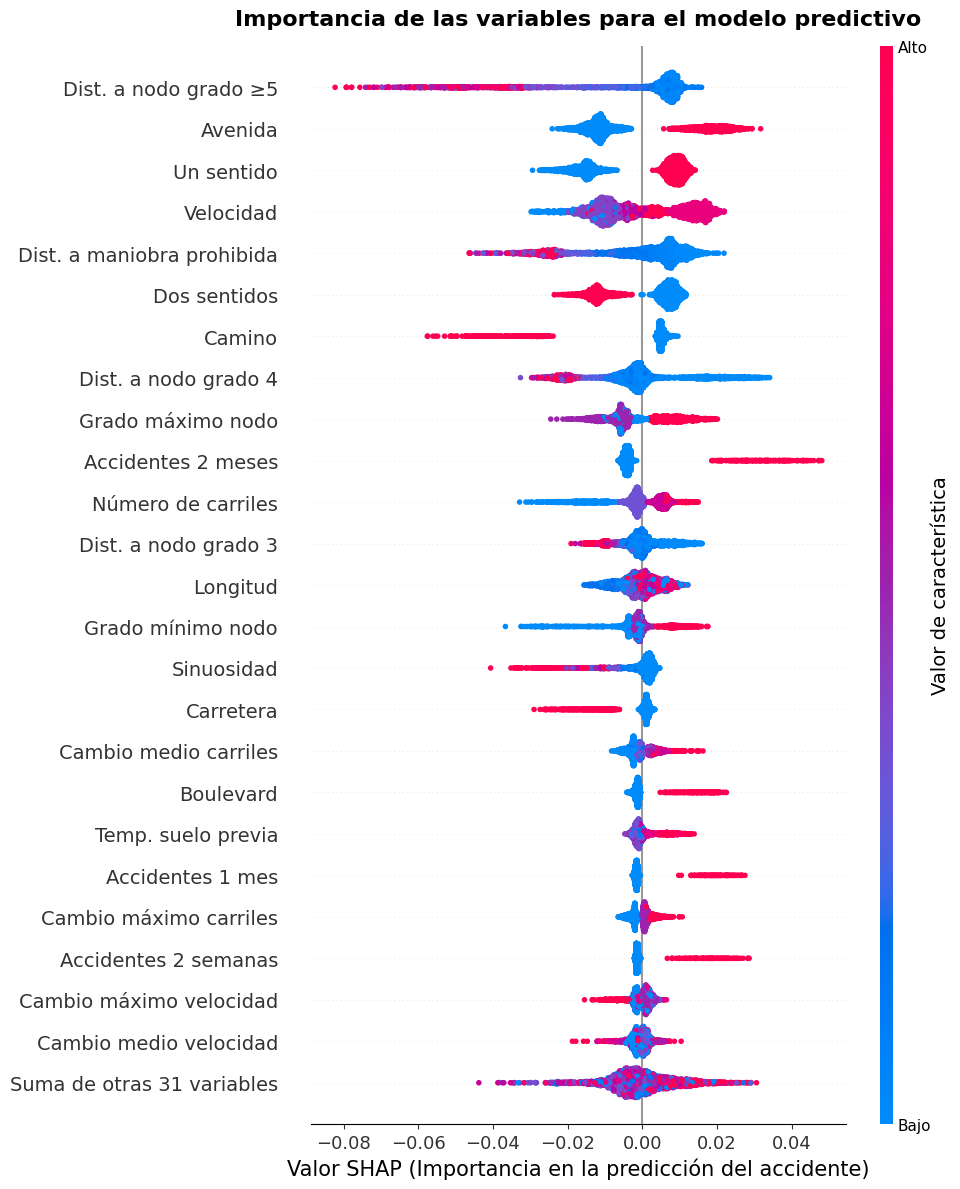

In [17]:
# GRÁFICO BEESWARM SHAP
plt.figure(figsize=(10, 12))

shap.plots.beeswarm(shap_explanation_holdout, max_display=25, show=False,s=16)

ax = plt.gca()
fig = plt.gcf()
fig.set_size_inches(10, 12)

traducir_etiquetas_shap(ax)
plt.gcf().axes[-1].set_ylabel("Valor de característica", fontsize=14)
cb_ax = plt.gcf().axes[-1]
cb_ax.set_yticklabels(["Bajo", "Alto"])
plt.xlabel("Valor SHAP (Importancia en la predicción del accidente)", fontsize=15)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 14)
plt.title('Importancia de las variables para el modelo predictivo',
          fontdict={"size":16, "weight":"bold"}, pad=15)
plt.tight_layout()
plt.show()

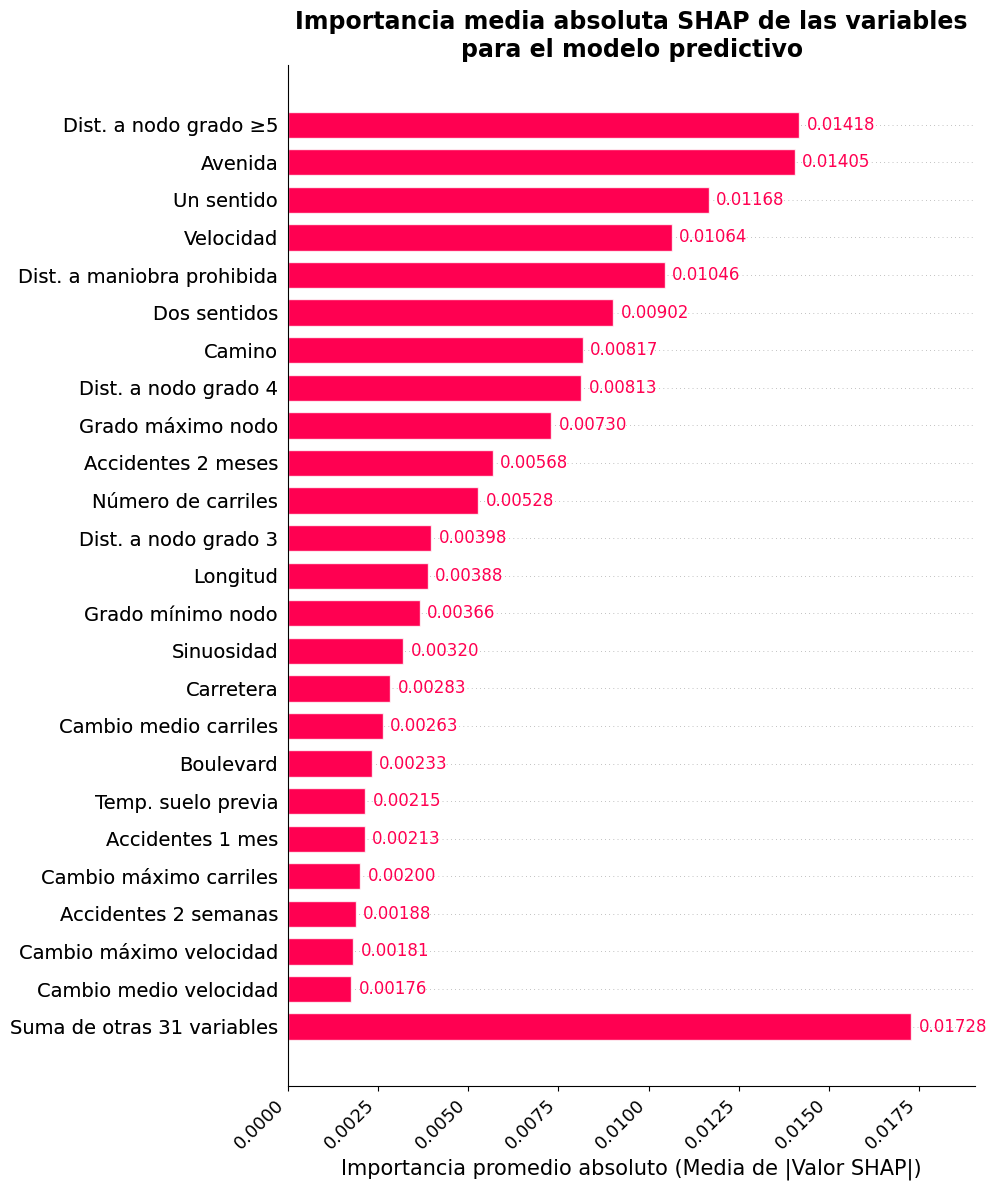

In [18]:
# GRÁFICO DE BARRAS SHAP
plt.figure(figsize=(10, 12))
n_var = 25
shap.plots.bar(shap_explanation_holdout, max_display=n_var, show=False
)

ax = plt.gca()
fig = plt.gcf()
fig.set_size_inches(10, 12)

traducir_etiquetas_shap(ax)

for text_obj, patch in zip(ax.texts, ax.patches):
    # patch.get_width() nos da el valor matemático real sin el recorte de SHAP
    valor_real = patch.get_width()
    text_obj.set_text(f"{valor_real:.5f}")

plt.xlabel("Importancia promedio absoluto (Media de |Valor SHAP|)", fontsize=15)
plt.title('Importancia media absoluta SHAP de las variables\npara el modelo predictivo',
          fontdict={"size":17, "weight":"bold"})

plt.xticks(rotation=45, ha='right', fontsize=13)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

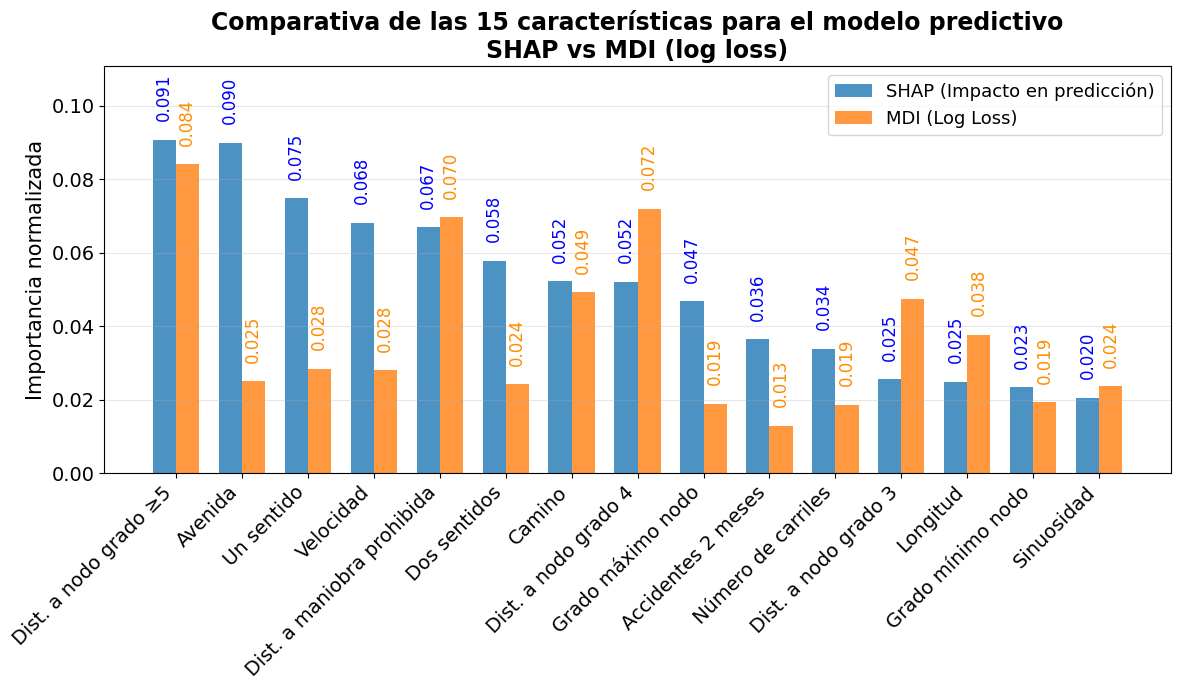

,Característica,SHAP (media absoluta),MDI media,SHAP Normalizado,MDI Normalizada,Ranking SHAP,Ranking MDI
0,Dist. a nodo grado ≥5,0.014178,0.084098,0.090820,0.084098,1,1
1,Avenida,0.014046,0.025095,0.089969,0.025095,2,17
2,Un sentido,0.011675,0.028473,0.074785,0.028473,3,15
3,Velocidad,0.010642,0.028057,0.068168,0.028057,4,16
4,Dist. a maniobra prohibida,0.010455,0.069646,0.066972,0.069646,5,3
5,Dos sentidos,0.009024,0.024197,0.057801,0.024197,6,18
6,Camino,0.008170,0.049171,0.052332,0.049171,7,4
7,Dist. a nodo grado 4,0.008131,0.072026,0.052083,0.072026,8,2
8,Grado máximo nodo,0.007299,0.018863,0.046753,0.018863,9,21
9,Accidentes 2 meses,0.005681,0.012905,0.036391,0.012905,10,25


In [19]:
# GRÁFICO COMPARATIVO SHAP VS IMPUREZA

# Importancia media absoluta de cada característica
comparativa = pd.DataFrame({
    'feature': X_shap_holdout.columns,
    'mean_abs_shap': np.abs(shap_vals_promedio).mean(axis=0),
    'importance_mean': importance_promedio
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

n_var = 15

# Normalizar para comparar en la misma escala
comparativa['shap_norm'] = comparativa['mean_abs_shap'] / comparativa['mean_abs_shap'].sum()
comparativa['importance_norm'] = comparativa['importance_mean'] / comparativa['importance_mean'].sum()
comparativa_n = comparativa.sort_values('shap_norm', ascending=False).head(n_var)

plt.subplots(figsize=(12, 7))
x = np.arange(len(comparativa_n))
width = 0.35

bars1 = plt.bar(x - width/2, comparativa_n['shap_norm'], width, 
               label='SHAP (Impacto en predicción)', color='#1f77b4', alpha=0.8)
bars2 = plt.bar(x + width/2, comparativa_n['importance_norm'], width, 
               label='MDI (Log Loss)', color='#ff7f0e', alpha=0.8)

# Texto
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f"{yval:.3f}", 
             ha='center', va='bottom', fontsize=12, color='blue', rotation=90)

for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f"{yval:.3f}", 
             ha='center', va='bottom', fontsize=12, color='darkorange', rotation=90)

plt.xticks(ticks=x, labels=comparativa_n['feature'], rotation=45, ha='right', fontsize=14)
plt.title(f'Comparativa de las {n_var} características para el modelo predictivo\nSHAP vs MDI (log loss)', 
             fontdict={"size":17, "weight":"bold"})
plt.ylabel('Importancia normalizada', fontsize=15)
plt.yticks(fontsize=14)
plt.ylim(0, max(comparativa_n['shap_norm'].max(), comparativa_n['importance_norm'].max()) * 1.22)
plt.legend(fontsize=13)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# Ranking SHAP (orden descendente)
comparativa['ranking_shap'] = comparativa['mean_abs_shap'].rank(
    method='dense', ascending=False
).astype(int)

# Ranking MDI (orden descendente)
comparativa['ranking_logloss'] = comparativa['importance_mean'].rank(
    method='dense', ascending=False
).astype(int)

comparativa = comparativa.rename(columns={
    'feature': 'Característica',
    'mean_abs_shap': 'SHAP (media absoluta)',
    'importance_mean': 'MDI media',
    'shap_norm': 'SHAP Normalizado',
    'importance_norm': 'MDI Normalizada',
    'ranking_shap': 'Ranking SHAP',
    'ranking_logloss': 'Ranking MDI',
})

display(comparativa)

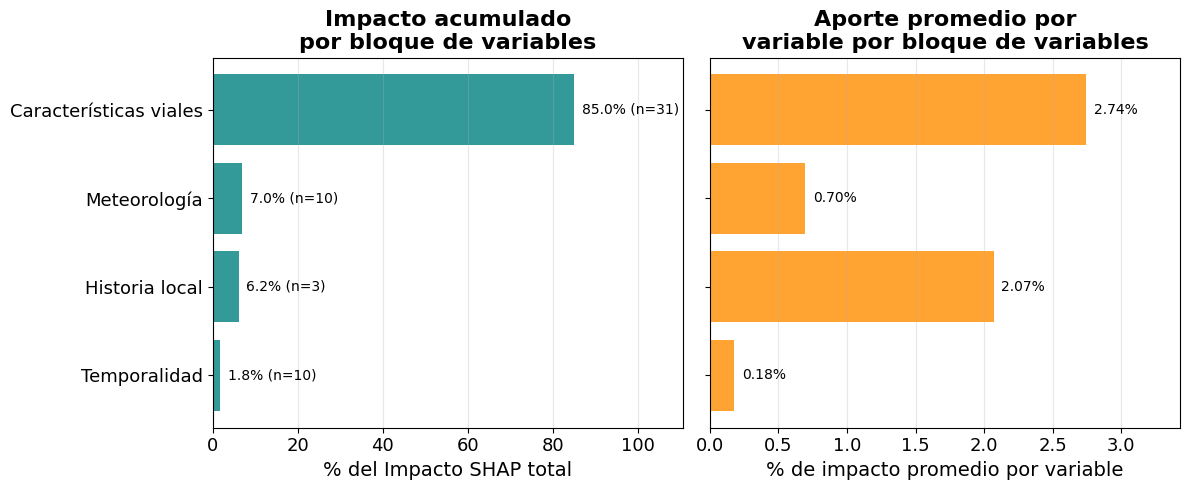

,Bloque Temático,Impacto total,No. variables,Impacto por variable,Porcentaje de impacto,Porcentaje por variable
3,Temporalidad,0.002793,10,0.000279,1.790042,0.179004
1,Historia local,0.009690,3,0.003230,6.210767,2.070256
2,Meteorología,0.010875,10,0.001087,6.970075,0.697008
0,Características viales,0.132661,31,0.004279,85.029115,2.742875


In [20]:
# IMPORTANCIA SHAP POR BLOQUE TEMÁTICO
vars_bloque = {
    "Dist. a nodo grado ≥5": "Características viales",
    "Camino": "Características viales",
    "Dist. a maniobra prohibida": "Características viales",
    "Dist. a nodo grado 4": "Características viales",
    "Velocidad viento previa": "Meteorología",
    "Humedad suelo previa": "Meteorología",
    "Cobertura nubes previa": "Meteorología",
    "Rachas viento previas": "Meteorología",
    "Temp. suelo previa": "Meteorología",
    "Temp. aparente previa": "Meteorología",
    "Temp. media previa": "Meteorología",
    "Temp. mínima previa": "Meteorología",
    "Dist. a nodo grado 3": "Características viales",
    "Longitud": "Características viales",
    "Sinuosidad": "Características viales",
    "Velocidad": "Características viales",
    "Cambio medio velocidad": "Características viales",
    "Avenida": "Características viales",
    "Cambio medio carriles": "Características viales",
    "Grado mínimo nodo": "Características viales",
    "Grado máximo nodo": "Características viales",
    "Un sentido": "Características viales",
    "Seno día semana": "Temporalidad",
    "Seno mes": "Temporalidad",
    "Coseno mes": "Temporalidad",
    "Número de carriles": "Características viales",
    "Cambio máximo velocidad": "Características viales",
    "Accidentes 2 meses": "Historia local",
    "Precipitación acumulada previa": "Meteorología",
    "Pandemia": "Temporalidad",
    "Precipitación máxima previa": "Meteorología",
    "Coseno día semana": "Temporalidad",
    "Boulevard": "Características viales",
    "Cambio máximo carriles": "Características viales",
    "Coseno franja horaria": "Temporalidad",
    "Circuito": "Características viales",
    "Vacaciones": "Temporalidad",
    "Dos sentidos": "Características viales",
    "Accidentes 2 semanas": "Historia local",
    "Seno franja horaria": "Temporalidad",
    "Accidentes 1 mes": "Historia local",
    "Carretera": "Características viales",
    "Privada": "Características viales",
    "Calle": "Características viales",
    "Festivo": "Temporalidad",
    "Cambio mínimo velocidad": "Características viales",
    "Promociónes departamentales": "Temporalidad",
    "Vía menor": "Características viales",
    "Nivel": "Características viales",
    "Cambio mínimo carriles": "Características viales",
    "Cerrada ambos sentidos": "Características viales",
    "Retorno en U": "Características viales",
    "Incorporación": "Características viales",
    "Evento FNSM": "Temporalidad",
    "Glorieta": "Características viales"
}

comparativa['Bloque Temático'] = comparativa['Característica'].map(vars_bloque)

# Agrupamiento
shap_por_bloque = comparativa.groupby('Bloque Temático').agg(
    **{
        'Impacto total': ('SHAP (media absoluta)', 'sum'),
        'No. variables': ('Característica', 'count')
    }
).reset_index()

# Calculo del impacto promedio por variable dentro del bloque
shap_por_bloque['Impacto por variable'] = shap_por_bloque['Impacto total'] / shap_por_bloque['No. variables']

# Calculo del porcentaje sobre el impacto total de todos los bloques
total_shap_absoluto = shap_por_bloque['Impacto total'].sum()
shap_por_bloque['Porcentaje de impacto'] = (shap_por_bloque['Impacto total'] / total_shap_absoluto) * 100

# Calculo de la eficiencia porcentual (qué % aporta una variable promedio de ese bloque)
shap_por_bloque['Porcentaje por variable'] = shap_por_bloque['Porcentaje de impacto'] / shap_por_bloque['No. variables']
# 3. ORDENAMOS ÚNICAMENTE por Impacto Total (Ascendente para que el mayor quede arriba)
shap_por_bloque = shap_por_bloque.sort_values('Porcentaje de impacto', ascending=True)

# GRAFICACIÓN
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Gráfico 1: Impacto total (volumen en %)
bars1 = ax1.barh(shap_por_bloque['Bloque Temático'], shap_por_bloque['Porcentaje de impacto'], color='teal', alpha=0.8)
ax1.set_title('Impacto acumulado\npor bloque de variables', fontsize=16, weight='bold')
ax1.set_xlabel('% del Impacto SHAP total', fontsize = 14)
ax1.tick_params(axis='x', labelsize=13)
ax1.tick_params(axis='y', labelsize=13)
ax1.grid(axis='x', alpha=0.3)

max_val1 = shap_por_bloque['Porcentaje de impacto'].max()
ax1.set_xlim(0, max_val1 * 1.3)

# Etiquetas
for bar, conteo in zip(bars1, shap_por_bloque['No. variables']):
    valor = bar.get_width()
    ax1.text(valor + (max_val1 * 0.02), bar.get_y() + bar.get_height()/2, 
             f"{valor:.1f}% (n={conteo})", va='center', fontsize=10, color='black')

# Gráfico 2: Eficiencia porcentual (impacto promedio por variable)
bars2 = ax2.barh(shap_por_bloque['Bloque Temático'], shap_por_bloque['Porcentaje por variable'], color='darkorange', alpha=0.8)
ax2.set_title('Aporte promedio por\nvariable por bloque de variables', fontsize=16, weight='bold')
ax2.set_xlabel('% de impacto promedio por variable', fontsize = 14)
ax2.tick_params(axis='x', labelsize=13)
ax2.grid(axis='x', alpha=0.3)

max_val2 = shap_por_bloque['Porcentaje por variable'].max()
ax2.set_xlim(0, max_val2 * 1.25)

# Etiquetas Gráfico 2
for bar in bars2:
    valor = bar.get_width()
    ax2.text(valor + (max_val2 * 0.02), bar.get_y() + bar.get_height()/2, 
             f"{valor:.2f}%", va='center', fontsize=10, color='black')

plt.tight_layout(w_pad=0.5)
plt.show()

display(shap_por_bloque)

## 8. Construcción de modelo final

Tras la validación del modelo base y del impacto positivo de la calibración isotónica del mismo, se ajusta el modelo final utilizando la totalidad del conjunto de datos de desarrollo (periodo 2019-2024). Para mantener la coherencia metodológica y evitar el sesgo por fuga de información temporal, la estimación de las probabilidades se ejecutó bajo el esquema de calibración cruzada temporal.

In [21]:
actualizar_modelo_final = False # Cambia a True cuando se quieravolver a entrenar este modelo
archivo_modelo_final = 'modelo_predictivo.pkl'

if actualizar_modelo_final or not os.path.exists(archivo_modelo_final):
    print("Entrenando Modelo Calibrado Final...")
    
    # ENTRENAR MODELO CALIBRADO FINAL
    # Configuración inicial
    tscv = TimeSeriesSplit(n_splits=5)
    # Para el modelo calibrado, se usa CalibratedClassifierCV pasando el tscv.
    rf_interno = RandomForestClassifier(**best_hypers, random_state=42, n_jobs=-1)
    modelo_calibrado = CalibratedClassifierCV(estimator=rf_interno, method='isotonic', cv=tscv)
    modelo_calibrado.fit(X_train, y_train)
    
    # Guardar el modelo recién entrenado
    joblib.dump(modelo_calibrado, archivo_modelo_final)
    print("Modelo final entrenado y guardado como archivo .pkl.")

else:
    # Cargar el modelo si ya existe
    print("Cargando Modelo Calibrado Final. Entrenamiento omitido...")
    modelo_calibrado = joblib.load(archivo_modelo_final)
    print("Modelo final cargado exitosamente.")

Cargando Modelo Calibrado Final. Entrenamiento omitido...
Modelo final cargado exitosamente.


## 9. Predicciones sobre instancias de prueba

Se realizan las predicciones para las diferentes instancias de prueba (para toda la red en diferentes franjas).

In [22]:
def predicciones_instancias(dir_instancias: str, csv_name: str, modelo, columnas_entrenamiento: list, gdf_red_vial: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """
    Genera un GeoDataFrame con predicciones dinámicas de probabilidad de accidentes
    para múltiples instancias temporales, integradas sobre la red vial.

    Parámetros
    ----------
    `dir_instancias`: Directorio donde se almacenan los archivos de instancias en 
        formato parquet y el CSV maestro.
    `csv_name`: Nombre del archivo CSV (sin extensión) que contiene la lista de identificadores de franjas horarias.
        Debe incluir la columna:
        - 'ID_INSTANCIA' : identificador único de cada franja temporal.
    `modelo`: Modelo entrenado con método `predict_proba` 
        para estimar probabilidades.
    `columnas_entrenamiento`: Lista de columnas utilizadas como 
        variables de entrada en el modelo.
    `gdf_red_vial`: Red vial base 
        con columnas:
        - 'ID_RED' : identificador de tramo vial.
        - 'geometry' : geometría del tramo.

    Retorna
    -------
    `gdf_resultado`: Copia de la red vial con columnas adicionales, una por cada franja horaria,
        conteniendo las probabilidades de accidente estimadas.
    """
    # Copia base con ID_RED y geometry
    gdf_resultado = gdf_red_vial[['ID_RED', 'geometry']].copy()
    csv = pd.read_csv(f"{dir_instancias}/{csv_name}.csv")
    
    id_franjas = csv['ID_INSTANCIA'].tolist()
    # Iterar sobre cada parquet en el directorio
    for id_franja in id_franjas:
        ruta = f"{dir_instancias}/{id_franja}.parquet"
        df = pd.read_parquet(ruta)
        X = df[columnas_entrenamiento]

        # Predicciones
        probs_cal = modelo.predict_proba(X)[:, 1]
        df['PROB'] = probs_cal
        
        # Merge con la red vial, solo ID_RED y predicciones
        gdf_temp = gdf_red_vial[['ID_RED']].merge(
            df[['ID_RED', 'PROB']], on='ID_RED', how='left'
        )
        
        # Renombrar la columna con el nombre del parquet
        gdf_resultado[id_franja] = gdf_temp['PROB']
    
    return gdf_resultado

# Predicciones sobre las instancias de prueba
dir_instancias = "Generados/Instancias_Prueba"
ruta_predicciones = "Generados/predicciones.parquet"

actualizar_predicciones = False  # Cambia a True si se quiere regenerar las predicciones
if actualizar_predicciones or not os.path.exists(ruta_predicciones):
    print("Generando predicciones sobre las instancias de prueba con el modelo final...")
    # Predicciones calibradas
    gdf_predicciones = predicciones_instancias(dir_instancias, 'relacion_instancias', modelo_calibrado, cols_train, gdf_rnc)
    gdf_predicciones.to_parquet(ruta_predicciones)
else:
    print("Cargando predicciones.")
    gdf_predicciones = pd.read_parquet(ruta_predicciones)
print("Predicciones terminadas")

Cargando predicciones.
Predicciones terminadas


### 9.1 Evaluaciones

Para observa el rendimiento de los mismos, se presentan métricas de desempeño geoespacial. La métrica fundamental que se utilizó es el PAI, calculada a partir de la relación entre el HR y la cobertura espacial (proporción de la red total marcada como de alto riesgo bajo el umbral $\tau$). De igual manera, se reportan las distribuciones y estadísticos de centralidad y dispersión de las probabilidades asignadas a cada tramo de la red vial, esto con la intención de complementar la información de los mapas y validar la adaptabilidad del modelo en las diferentes instancias.

In [23]:
# Umbrales de clasificación
archivo_umbral = 'umbral_config.json'
with open(archivo_umbral, 'r') as f:
        config_umbral = json.load(f)
        
umbral = config_umbral["umbral_calibrado"]
print(f"Umbral de clasificación cargado: {umbral}")

# Lectura de las relaciones de las instancias
ruta_del_csv = "Generados/Instancias_Prueba/relacion_instancias.csv"
df_relacion = pd.read_csv(ruta_del_csv)

actualizar_resultados = False   # Cambia a True si se quiere recalcular las métricas de evaluación
ruta_eval = "Generados/evaluaciones_predictivo.csv"

if actualizar_resultados or not os.path.exists(ruta_eval):
    print("Generando evaluaciones...")
    resultados = []

    # Pre-calcular longitud total de la red y preparar base geo
    total_km_red = gdf_rnc['LONGITUD'].sum()
    df_geo_base = gdf_rnc[['ID_RED', 'LONGITUD']].copy()

    # Iterar sobre las filas del CSV
    for index, row in df_relacion.iterrows():
        id_franja = row['ID_INSTANCIA']
        
        # Validación rápida por si la franja no está en las predicciones
        if id_franja not in gdf_predicciones.columns:
            print(f"Aviso: No se encontraron predicciones para la franja {id_franja}")
            continue
            
        # Extraer FECHA_FRANJA del CSV
        fecha_franja = row['FECHA_FRANJA'] 
        
        # Accidentes reales
        accidentes_franja = df_acc[df_acc['FECHA_FRANJA'] == fecha_franja]
        total_accidentes = len(accidentes_franja)
        ids_con_accidente = accidentes_franja['ID_RED'].unique()
        
        # Extraer probabilidades ya precalculadas de las columnas
        probs = gdf_predicciones[id_franja]
        
        # Crear un DataFrame temporal con los riesgos clasificados según los umbrales
        df_temp = pd.DataFrame({
            'ID_RED': gdf_predicciones['ID_RED'],
            'riesgo_alto': (probs >= umbral).astype(int)
        })
        
        # Longitudes para calcular Cobertura
        df_geo = df_temp.merge(df_geo_base, on='ID_RED', how='left')

        # Cálculo de cobertura: proporción de km de la red clasificados como de alto riesgo
        km_riesgo = df_geo[df_geo['riesgo_alto'] == 1]['LONGITUD'].sum()
        cobertura= km_riesgo / total_km_red if total_km_red > 0 else 0
        
        # Calculo del PAI y Hit Rate
        if total_accidentes > 0:
            tramos_alto = df_geo[df_geo['riesgo_alto'] == 1]['ID_RED']
            n_capturados = accidentes_franja['ID_RED'].isin(tramos_alto).sum()
            hit_rate = n_capturados / total_accidentes
            pai = hit_rate / cobertura if cobertura > 0 else 0
        else:
            n_capturados = 0
            hit_rate, pai = np.nan, np.nan

        # Guardar métricas
        resultados.append({
            'ID_INSTANCIA': id_franja,
            'Capturados': n_capturados,
            'Cobertura': cobertura,
            'Hit Rate': hit_rate,
            'PAI': pai,
            'Prob_Max': probs.max()
        })
            
    # Convertir los resultados a DataFrame
    df_metricas = pd.DataFrame(resultados)
    cols = df_relacion.columns.tolist()
    cols.remove("TOTAL_ACCIDENTES")
    cols.append("TOTAL_ACCIDENTES")
    df_relacion = df_relacion[cols]
    df_resultados = pd.merge(df_relacion, df_metricas, on='ID_INSTANCIA', how='left')
    df_resultados.to_csv(ruta_eval, index=False)
else:
    print("Omitiendo calculo de evaluaciones")
    df_resultados = pd.read_csv(ruta_eval)
# Mostrar y guardar
display(df_resultados)

Umbral de clasificación cargado: 0.19187358916478556
Omitiendo calculo de evaluaciones


,ID_INSTANCIA,ID_FRANJA,FECHA_FRANJA,METODOLOGIA,MES,DIA,FRANJA,FESTIVO,FNSM,VACACIONES,PROMOCION,PANDEMIA,WIND_SPEED_MEAN_PREV,SOIL_MOISTURE_MEAN_PREV,APP_TEMP_MEAN_PREV,TEMP_MEAN_PREV,WIND_GUSTS_MAX_PREV,SOIL_TEMP_MEAN_PREV,TEMP_MIN_PREV,CLOUD_COVER_MEAN_PREV,PRECIP_SUM_PREV,PRECIP_MAX_PREV,TOTAL_ACCIDENTES,Capturados,Cobertura,Hit Rate,PAI,Prob_Max
0,Instancia_1,CLIMA_01_LLUVIA,2024-07-20 18:00:00,CLIMA_CONTRASTE,Julio,Sábado,18:00 - 0:00,0,0,1,0,0,6.223333,0.378000,23.970049,22.449999,26.639999,25.074999,21.049999,80.666664,1.2,0.9,1,1,0.171475,1.000000,5.831765,0.353078
1,Instancia_2,CLIMA_01_SECO,2024-04-20 18:00:00,CLIMA_CONTRASTE,Abril,Sábado,18:00 - 0:00,0,1,0,0,0,20.610901,0.119000,26.230268,30.633333,49.320000,35.875000,28.850000,21.833334,0.0,0.0,5,3,0.254378,0.600000,2.358693,0.375545
2,Instancia_3,CLIMA_02_LLUVIA,2024-06-07 18:00:00,CLIMA_CONTRASTE,Junio,Viernes,18:00 - 0:00,0,0,0,0,0,8.302051,0.122333,28.905115,29.824999,45.360001,39.600002,27.700001,50.000000,0.6,0.5,3,3,0.260436,1.000000,3.839716,0.394140
3,Instancia_4,CLIMA_02_SECO,2024-12-13 18:00:00,CLIMA_CONTRASTE,Diciembre,Viernes,18:00 - 0:00,0,0,0,0,0,6.520466,0.146500,21.412683,23.525335,22.320000,25.033333,21.944000,34.166668,0.0,0.0,3,2,0.165485,0.666667,4.028562,0.377277
4,Instancia_5,CLIMA_03_LLUVIA,2024-07-26 12:00:00,CLIMA_CONTRASTE,Julio,Viernes,12:00 - 18:00,0,0,1,0,0,5.356384,0.428500,16.962034,16.158333,17.280001,17.525000,15.300000,100.000000,5.9,2.9,1,1,0.139088,1.000000,7.189693,0.526552
5,Instancia_6,CLIMA_03_SECO,2024-08-23 12:00:00,CLIMA_CONTRASTE,Agosto,Viernes,12:00 - 18:00,0,0,1,0,0,6.870167,0.212667,17.525034,17.275000,21.600000,18.941668,13.450000,25.500000,0.0,0.0,1,1,0.192408,1.000000,5.197300,0.391439
6,Instancia_7,CLIMA_04_LLUVIA,2024-07-12 06:00:00,CLIMA_CONTRASTE,Julio,Viernes,6:00 - 12:00,0,0,0,0,0,5.864383,0.339833,15.970401,15.407666,15.120000,17.240999,14.850000,95.500000,0.6,0.2,0,0,0.176594,NaN,NaN,0.500905
7,Instancia_8,CLIMA_04_SECO,2024-11-08 06:00:00,CLIMA_CONTRASTE,Noviembre,Viernes,6:00 - 12:00,0,0,0,0,0,4.691383,0.136000,13.656250,14.491666,12.240000,16.591667,13.039500,55.166668,0.0,0.0,2,2,0.171046,1.000000,5.846374,0.379885
8,Instancia_9,CLIMA_05_LLUVIA,2024-07-08 18:00:00,CLIMA_CONTRASTE,Julio,Lunes,18:00 - 0:00,0,0,0,0,0,6.192450,0.267167,25.941534,23.908333,33.480000,27.975000,19.750000,76.500000,6.9,5.3,1,1,0.164643,1.000000,6.073734,0.395243
9,Instancia_10,CLIMA_05_SECO,2024-04-29 18:00:00,CLIMA_CONTRASTE,Abril,Lunes,18:00 - 0:00,0,1,0,0,0,11.709816,0.119000,25.548082,28.683332,32.759998,35.450001,26.650000,76.833336,0.0,0.0,2,2,0.217185,1.000000,4.604365,0.369538


,Conteo,Media,Desv. Est.,Mín,25%,50%,75%,Máx,IQR
Variable,,,,,,,,,
Cobertura,60.0,0.1792,0.0289,0.1391,0.1652,0.1719,0.1803,0.2764,0.0150
Hit Rate,52.0,0.7805,0.3060,0.0000,0.6000,1.0000,1.0000,1.0000,0.4000
PAI,52.0,4.4209,1.8140,0.0000,3.3053,5.2327,5.7738,7.1897,2.4685


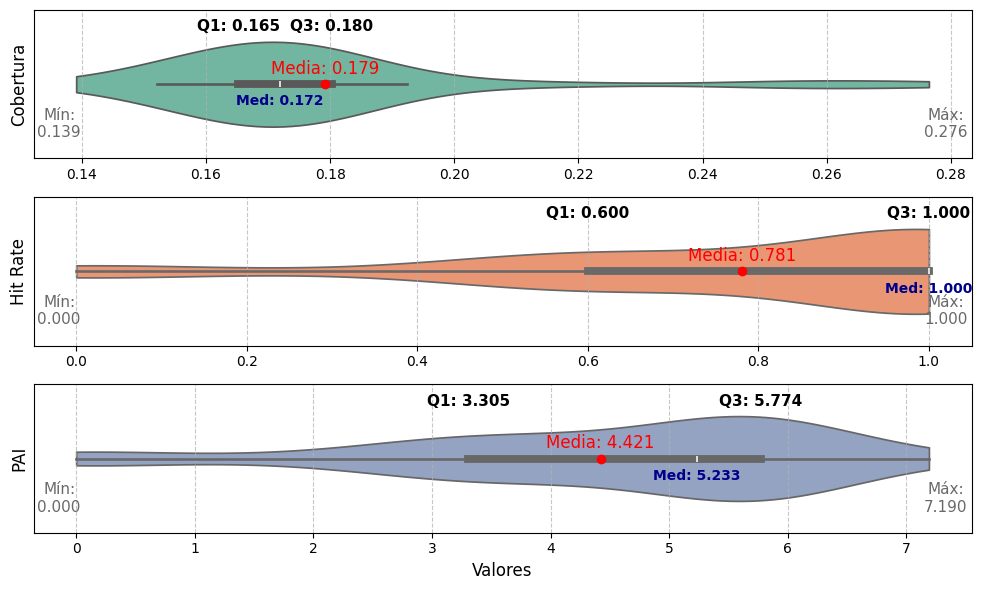

In [24]:
# ESTADÍSTICAS
cols = [
    'Cobertura', 'Hit Rate', 'PAI'
]

# Calcular describe y transponer para que cada fila sea una variable
resumen = df_resultados[cols].describe().T

# Agregar IQR
resumen['IQR'] = resumen['75%'] - resumen['25%']
resumen.rename(columns = {"count":"Conteo", "mean":"Media", "std": "Desv. Est.", "min":"Mín", "max":"Máx"}, inplace = True)

# Formatos
resumen = resumen.round(4)
resumen.index.name = 'Variable'
display(resumen)

# Extraer colores de la paleta
colores = sns.color_palette("Set2")

# Crear subplots (uno por variable)
fig, axes = plt.subplots(len(cols), 1, figsize=(10, 6))

for i, col in enumerate(cols):
    ax = axes[i]
    
    # Generar violín
    sns.violinplot(
        x=df_resultados[col], 
        ax=ax, 
        orient="h", 
        color=colores[i], 
        cut=0,          
        inner="box"     
    )

    # Configuraciones
    ax.set_title("")
    ax.set_ylabel(col, fontsize=12)
    ax.set_yticks([])
    if i != len(cols) - 1:
        ax.set_xlabel("")
    else:
        ax.set_xlabel("Valores", fontsize=12)
    ax.grid(axis='x', linestyle='--', alpha=0.7)

    # Calcular estadísticos clave
    val_min = df_resultados[col].min()
    q1 = df_resultados[col].quantile(0.25)
    mediana = df_resultados[col].median()
    media = df_resultados[col].mean()
    q3 = df_resultados[col].quantile(0.75)
    val_max = df_resultados[col].max()

    # Posición vertical base
    y_pos = 0 
    # Calcular el rango de los datos para esta columna
    rango = val_max - val_min
    # Definir el margen como un pequeño porcentaje del ancho total
    margen = rango * 0.02 

    # Anotaciones Mínimo y Máximo
    ax.text(val_min - margen, y_pos - 0.5, f'Mín:\n{val_min:.3f}', ha='center', size=11, color='dimgrey')
    ax.text(val_max + margen, y_pos - 0.5, f'Máx:\n{val_max:.3f}', ha='center', size=11, color='dimgrey')

    # Anotaciones Cuartiles y Mediana
    ax.text(q1, y_pos + 0.5, f'Q1: {q1:.3f}', ha='center', size=11, weight='semibold')
    ax.text(mediana, y_pos - 0.2, f'Med: {mediana:.3f}', ha='center', size=10, color='darkblue', weight='bold')
    ax.text(q3, y_pos + 0.5, f'Q3: {q3:.3f}', ha='center', size=11, weight='semibold')

    # Anotación Media
    ax.plot(media, y_pos, marker='o', color='red', markersize=6)
    ax.text(media, y_pos + 0.1, f'Media: {media:.3f}', ha='center', size=12, color='red')

    # Ampliar los límites del eje Y para que los textos no queden fuera de la figura
    ax.set_ylim(-0.7, 0.7)
# Ajustar espacios
plt.tight_layout()
plt.show()

### 9.2 Concentración espacial de desempeño

Se realiza un análisis espacial de desempeño de acuerdo a la cobertura vial.

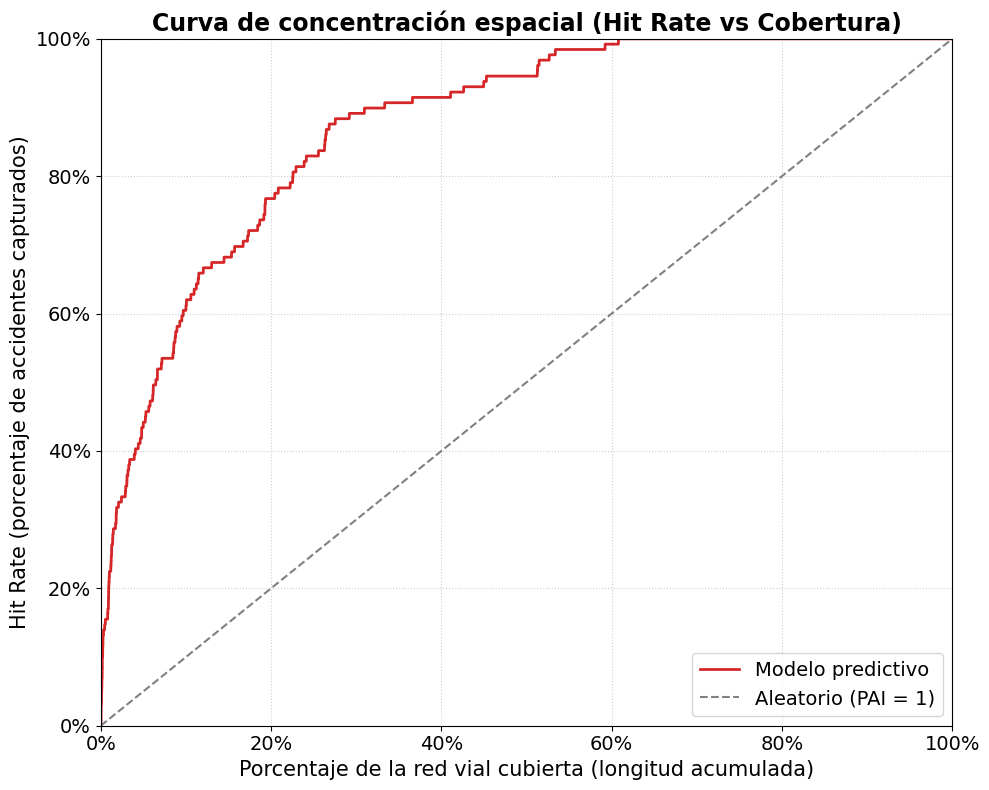

In [25]:
# Accidentes reales
df_acc_merge = df_acc[['FECHA_FRANJA', 'ID_RED']].drop_duplicates()
df_acc_merge['FECHA_FRANJA'] = pd.to_datetime(df_acc_merge['FECHA_FRANJA'])
df_relacion['FECHA_FRANJA'] = pd.to_datetime(df_relacion['FECHA_FRANJA'])
df_acc_merge = df_acc_merge.merge(df_relacion[['ID_INSTANCIA', 'FECHA_FRANJA']], on='FECHA_FRANJA', how='inner')
df_acc_merge['ACCIDENTE'] = 1
df_acc_merge = df_acc_merge[['ID_INSTANCIA', 'ID_RED', 'ACCIDENTE']]

# Formato Largo
cols_instancias = df_relacion['ID_INSTANCIA'].tolist()

df_cal_long = pd.melt(
    gdf_predicciones.drop(columns='geometry'), 
    id_vars=['ID_RED'], 
    value_vars=cols_instancias,
    var_name='ID_INSTANCIA', 
    value_name='PROB'
)

# DataFrame de evaluación
df_eval = df_cal_long.merge(gdf_rnc[['ID_RED', 'LONGITUD']], on='ID_RED', how='left')
df_eval = df_eval.merge(df_acc_merge, on=['ID_RED', 'ID_INSTANCIA'], how='left')
df_eval['ACCIDENTE'] = df_eval['ACCIDENTE'].fillna(0) # 0 para tramos sin accidente

# FUNCIÓN PARA CALCULAR LA CURVA DE CONCENTRACIÓN DE ACCIDENTES
def calcular_curva_concentracion(df: pd.DataFrame, col_prob: str) -> pd.DataFrame:
    """
    Calcula la curva de concentración de accidentes en función de las probabilidades
    estimadas para cada tramo vial.

    Parámetros
    ----------
    `df`: DataFrame con información de tramos viales. 
        Debe incluir:
        - 'LONGITUD': longitud del tramo vial.
        - 'ACCIDENTE': indicador binario (0/1) de accidente en el tramo.
        - col_prob: columna con las probabilidades estimadas (ej. 'PROB_BASE' o 'PROB_CAL').
    `col_prob`: Nombre de la columna de probabilidades a 
        utilizar para ordenar los tramos.

    Retorna
    -------
    `df_sorted`: DataFrame ordenado y enriquecido 
        con columnas:
        - 'LONGITUD_ACUM': longitud acumulada.
        - 'ACCIDENTES_ACUM': accidentes acumulados.
        - 'Cobertura': proporción de longitud cubierta (0 a 1).
        - 'Hit Rate': proporción de accidentes capturados (0 a 1).
    """
    # Ordenar de mayor a menor probabilidad
    df_sorted = df.sort_values(by=col_prob, ascending=False).copy()
    
    # Acumulados
    df_sorted['LONGITUD_ACUM'] = df_sorted['LONGITUD'].cumsum()
    df_sorted['ACCIDENTES_ACUM'] = df_sorted['ACCIDENTE'].cumsum()
    
    # Normalizar a porcentajes (0 a 1)
    total_longitud = df_sorted['LONGITUD'].sum()
    total_accidentes = df_sorted['ACCIDENTE'].sum()
    
    df_sorted['Cobertura'] = df_sorted['LONGITUD_ACUM'] / total_longitud
    df_sorted['Hit Rate'] = df_sorted['ACCIDENTES_ACUM'] / total_accidentes
    
    return df_sorted.reset_index(drop=True)

# Generar las curvas completas
curva_cal = calcular_curva_concentracion(df_eval, 'PROB')

plt.figure(figsize=(10, 8))
plt.plot(curva_cal['Cobertura'], curva_cal['Hit Rate'], label='Modelo predictivo', color='#d62728', linewidth=2)

# Línea base
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Aleatorio (PAI = 1)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.title('Curva de concentración espacial (Hit Rate vs Cobertura)', fontsize=17, fontweight = "bold")
plt.xlabel('Porcentaje de la red vial cubierta (longitud acumulada)', fontsize=15)
plt.ylabel('Hit Rate (porcentaje de accidentes capturados)', fontsize=15)
plt.legend(loc="lower right", fontsize=14)
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [26]:
# FUNCIÓN PARA EXTRAER PUNTOS CLAVE DE LA CURVA DE CONCENTRACIÓN
def extraer_puntos_clave(curva: pd.DataFrame, col_prob: str) -> pd.DataFrame:
    """
    Extrae puntos clave de la curva de concentración para niveles de cobertura predefinidos,
    generando una tabla con métricas comparativas.

    Parámetros
    ----------
    `curva`: DataFrame resultante de `calcular_curva_concentracion`, 
        debe incluir:
        - 'Cobertura': proporción acumulada de longitud cubierta.
        - 'Hit Rate': proporción acumulada de accidentes capturados.
        - col_prob: columna de probabilidades (ej. 'PROB_BASE' o 'PROB_CAL').
    `col_prob`: Nombre de la columna de probabilidades 
        usada para ordenar los tramos.
    `nombre_modelo`: Etiqueta del modelo evaluado 
        (ej. 'Base', 'Calibrado').

    Retorna
    -------
    `resultados`: Dataframe con 
        columnas:
        - 'Modelo' : nombre del modelo evaluado.
        - 'Cobertura_Objetivo' : nivel objetivo (ej. "10%").
        - 'Cobertura_Real' : cobertura acumulada alcanzada.
        - 'Hit Rate' : proporción de accidentes capturados.
        - 'PAI' : índice de concentración (Hit Rate / Cobertura).
        - 'Umbral_Implícito' : probabilidad mínima asociada al nivel.
    """

    niveles = np.arange(0.05, 0.5, 0.05) # Barre de 5% a 50% en pasos de 5%
    resultados = []
    
    for n in niveles:
        # Índice donde la cobertura acumulada supera el nivel n
        idx = (curva['Cobertura'] - n).abs().idxmin()
        row = curva.loc[idx]
        
        resultados.append({
            'Cobertura Objetivo': f"{n*100:.0f}%",
            'Cobertura Real': row['Cobertura'],
            'Hit Rate': row['Hit Rate'],
            'PAI': row['Hit Rate'] / row['Cobertura'] if row['Cobertura'] > 0 else 0,
            'Umbral implícito': row[col_prob]
        })
    return pd.DataFrame(resultados)
# Generar y mostrar la tabla comparativa
tabla_cal = extraer_puntos_clave(curva_cal, 'PROB')
df_tabla_comparativa = tabla_cal.reset_index(drop=True)
display(df_tabla_comparativa)

,Cobertura Objetivo,Cobertura Real,Hit Rate,PAI,Umbral implícito
0,5%,0.05,0.441860,8.837210,0.277321
1,10%,0.10,0.612403,6.124034,0.235652
2,15%,0.15,0.682171,4.547799,0.206718
3,20%,0.20,0.767442,3.837211,0.181644
4,25%,0.25,0.829457,3.317829,0.162359
5,30%,0.30,0.891473,2.971576,0.141613
6,35%,0.35,0.906977,2.591362,0.124043
7,40%,0.40,0.914729,2.286822,0.110698
8,45%,0.45,0.937984,2.084410,0.097804


## 10. Mapas de riesgo

Las estimaciones probabilísticas calibradas resultantes constituyen la representación cuantitativa del riesgo dinámico en la red vial, las cuales son integradas directamente en la siguiente fase como la demanda ponderada que alimenta el modelo de optimización prescriptiva de localización de recursos.

### 10.1 Lectura de datos

In [27]:
# Cargar las predicciones del RF calibrado
gdf_predicciones = gpd.read_parquet("Generados/predicciones.parquet")
print("Predicciones del RF calibrado cargadas")

# Cargar los resultados ya generados
df_resultados = pd.read_csv("Generados/evaluaciones_predictivo.csv")
print("Resultados cargados")

# Cargar los datos de accidentes
df_acc = pd.read_parquet("Generados/accidentes_franjas.parquet")
print("Datos de accidentes cargados")

Predicciones del RF calibrado cargadas
Resultados cargados
Datos de accidentes cargados


In [28]:
# Umbrales de clasificación
archivo_umbral = 'umbral_config.json'
with open(archivo_umbral, 'r') as f:
        config_umbral = json.load(f)
        
umbral = config_umbral["umbral_calibrado"]
print(f"Umbral de clasificación cargado: {umbral}")

# Calculo de probabilidad máxima del modelo calibrado
prob_max= df_resultados['Prob_Max'].max()
print(f"Probabilidad máxima del modelo calibrado encontrada: {prob_max:.4f}")

Umbral de clasificación cargado: 0.19187358916478556
Probabilidad máxima del modelo calibrado encontrada: 0.5388


### 10.3 Funciones de graficación

In [29]:
# FUNCION DE FORMATO
def obtener_stats_formateadas(probs: np.ndarray, umbral: float) -> list[list[str]]:
    """
    Calcula y devuelve estadísticas formateadas de un arreglo de probabilidades,
    separadas en tres grupos: todas, por debajo del umbral y por encima/igual al umbral.

    Parámetros
    ----------
    probs: Arreglo unidimensional de probabilidades 
        (valores float entre 0 y 1).
    umbral: Valor de corte para dividir las probabilidades 
        en dos subconjuntos:
        - p_bajo : valores < umbral
        - p_alto : valores >= umbral

    Retorna
    -------
    stats : Lista con tres filas (listas internas), 
        cada una con cinco columnas:
        - Conteo y porcentaje (ej. "12 (34.5%)")
        - Media (ej. "0.4567")
        - Desviación estándar (ej. "0.1234")
        - Mediana (ej. "0.4000")
        - Máximo (ej. "0.8900")

        Orden de filas:
        1. Estadísticas de todas las probabilidades.
        2. Estadísticas de subconjunto < umbral.
        3. Estadísticas de subconjunto >= umbral.
    """    
    if len(probs) == 0:
        return [["-", "-", "-", "-", "-"]] * 3

    total = len(probs)

    p_bajo = probs[probs < umbral]
    p_alto = probs[probs >= umbral]

    def calc_row(p_array):
        if len(p_array) == 0:
            return ["0 (0.0%)", "-", "-", "-", "-"]

        std_val = f"{p_array.std():.4f}" if len(p_array) > 1 else "0.0000"
        porcentaje = (len(p_array) / total) * 100

        return [
            f"{len(p_array):,} ({porcentaje:.1f}%)",
            f"{p_array.mean():.4f}",
            std_val,
            f"{np.median(p_array):.4f}",
            f"{p_array.max():.4f}"
        ]

    return [calc_row(probs), calc_row(p_bajo), calc_row(p_alto)]

def distribucion_riesgo(
    id_instancia: str,
    csv_resultados: pd.DataFrame,
    gdf_calibradas: gpd.GeoDataFrame,
    umbral_cal: float,
    df_accidentes: pd.DataFrame,
    num_clases: int = 30
) -> None:
    """
    Genera visualizaciones (histograma y violin plot) de la distribución
    de probabilidades de accidente para una franja temporal específica
    utilizando el modelo calibrado.

    Parámetros
    ----------
    `id_instancia`: Nombre de la columna en gdf_calibradas que contiene las predicciones
        para la franja temporal.
    `csv_resultados`: DataFrame con relación entre ID_INSTANCIA y FECHA_FRANJA.
        Debe incluir columnas:
        - 'ID_INSTANCIA'
        - 'FECHA_FRANJA'
    `gdf_calibradas`: GeoDataFrame con predicciones del modelo calibrado.
    `umbral_cal`: Umbral de decisión para el modelo calibrado.
    `df_accidentes`: Histórico de accidentes con columna 'FECHA_FRANJA'.
    `num_clases`: Número de bins del histograma (default=30).

    Retorna
    -------
    None
        La función genera, muestra y guarda directamente la figura con Matplotlib/Seaborn.
    """

    # Predicciones
    probs_cal = gdf_calibradas[id_instancia].dropna().values

    # Límite superior dinámico y ticks
    limites_clases = np.linspace(0.0, 1.0, num_clases + 1)
    ticks_eje_x = np.arange(0.0, 1.1, 0.1)

    # Accidentes de la franja
    fecha_franja = csv_resultados[csv_resultados['ID_INSTANCIA'] == id_instancia]['FECHA_FRANJA'].values[0]
    franja_dt = pd.to_datetime(fecha_franja, dayfirst=False)

    df_acc_copy = df_accidentes.copy()
    df_acc_copy['Franja_Str'] = pd.to_datetime(df_acc_copy['FECHA_FRANJA']).dt.strftime('%Y-%m-%d %H:%M')
    franja_str = franja_dt.strftime('%Y-%m-%d %H:%M')
    total_accidentes = int(df_acc_copy[df_acc_copy['Franja_Str'] == franja_str].shape[0])

    dia = franja_dt.normalize()
    ini = franja_dt.strftime("%H:%M:%S")
    fin = (franja_dt + pd.Timedelta(hours=6) - pd.Timedelta(seconds=1)).strftime("%H:%M:%S")
    texto_etiqueta = f"{id_instancia}\n{dia.strftime('%Y-%m-%d')}\n{ini}-{fin}\n({total_accidentes} accidentes)"

    # Configuración de la figura
    fig = plt.figure(figsize=(20, 9))

    # Sub-grid (1 columna, 2 filas: Histograma arriba, Violin plot abajo)
    gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[3.5, 1], hspace=0.08)
    gs.update(top=0.72, bottom=0.08, left=0.2, right=0.9)

    ax_hist_cal = fig.add_subplot(gs[0, 0])
    ax_viol_cal = fig.add_subplot(gs[1, 0])

    # Etiqueta lateral izquierda (anclada al histograma)
    ax_hist_cal.annotate(
        texto_etiqueta, xy=(-0.05, 0.5), xycoords='axes fraction',
        xytext=(-90, 0), textcoords='offset points',
        ha='center', va='center', rotation=90,
        fontsize=23, fontweight='bold', color='#333333',
        multialignment='center'
    )

    # Histogramas y curva KDE
    sns.histplot(probs_cal, color='#66b3ff', kde=True, bins=limites_clases, ax=ax_hist_cal)
    ax_hist_cal.axvline(
        umbral_cal, color='blue', linestyle='--', linewidth=2,
        label=f'Umbral ({umbral_cal:.4f})'
    )
    ax_hist_cal.set_ylabel('Nº Calles', fontsize=19)

    # Tabla descriptiva superior
    stats_cal = obtener_stats_formateadas(probs_cal, umbral_cal)
    tabla_cal = ax_hist_cal.table(
        cellText=stats_cal,
        rowLabels=['Global', '< Umbral', '>= Umbral'],
        colLabels=['Nº Tramos', 'Media', 'Desv. Est.', 'Mediana', 'Máximo'],
        loc='top',
        bbox=[0.14, 1.05, 0.86, 0.28], 
        cellLoc='center'
    )
    tabla_cal.auto_set_font_size(False)
    tabla_cal.set_fontsize(19)
    for (fila, col), celda in tabla_cal.get_celld().items():
        if fila == 0 or col == -1:
            celda.set_text_props(weight='bold')

    # Grafico de violin
    sns.violinplot(x=probs_cal, color='#66b3ff', inner="quart", ax=ax_viol_cal, linewidth=1.5)
    ax_viol_cal.axvline(umbral_cal, color='blue', linestyle='--', linewidth=2)
    ax_viol_cal.set_yticks([])

    # Configuración de ejes x
    for ax in [ax_hist_cal, ax_viol_cal]:
        ax.set_xlim(0.0, 1.0)
        ax.set_xticks(ticks_eje_x)
        ax.tick_params(axis='both', labelsize=18)

    ax_hist_cal.tick_params(labelbottom=False, labelsize=18)
    ax_viol_cal.set_xlabel('Probabilidad de Accidente', fontsize=20)
    ax_hist_cal.legend(loc='upper right', fontsize=19)

    # Guardado de la Figura
    ruta_directorio = "Outputs/Distribución de riesgo"
    os.makedirs(ruta_directorio, exist_ok=True)

    ruta_archivo = os.path.join(ruta_directorio, f"{id_instancia}.png")
    plt.savefig(ruta_archivo, dpi=300, bbox_inches='tight')
    plt.close(fig)

def mapas_riesgo(
    id_instancia: str,
    csv_resultados: pd.DataFrame,
    gdf_calibradas: gpd.GeoDataFrame,
    df_accidentes: pd.DataFrame,
    umbral_cal: float,
    prob_max: float,
    factor_zoom: float = 0.18
) -> None:
    """
    Genera mapas de riesgo de accidentes (completo y con zoom) para una instancia temporal 
    específica, utilizando las predicciones del modelo calibrado.

    Parámetros
    ----------
    `id_instancia`: Identificador de la franja temporal 
        (columna en gdf_calibradas).
    `csv_resultados`: DataFrame con relación entre ID_INSTANCIA y FECHA_FRANJA.
        Debe incluir columnas:
        - 'ID_INSTANCIA'
        - 'FECHA_FRANJA'
        - 'Capturados', 'Cobertura', 'Hit Rate', 'PAI'
    `gdf_calibradas`: GeoDataFrame con predicciones del modelo calibrado.
    `df_accidentes`: Histórico de accidentes con columnas:
        - 'ID_RED'
        - 'FECHA_FRANJA'
    `umbral_cal`: Umbral de decisión para el modelo calibrado.
    `prob_max`: Probabilidad máxima para la escala de graficación.
    `factor_zoom`: Proporción del área total usada para el recorte con zoom
        (default=0.18).

    Retorna
    -------
    None
        La función genera y guarda directamente las figuras (completa y zoom)
        en archivos PNG dentro de: "Outputs/Mapas de riesgo".
    """
    id_franja = id_instancia

    # Extraer métricas precalculadas
    metricas = csv_resultados[csv_resultados['ID_INSTANCIA'] == id_instancia].iloc[0]
    
    # Fecha de la franja horaria
    fecha_franja = metricas['FECHA_FRANJA']
    franja_dt = pd.to_datetime(fecha_franja, dayfirst=False)

    # Preparar GeoDataFrame con predicciones
    df_merge = gdf_calibradas[['ID_RED', 'geometry']].copy()
    df_merge['prob'] = gdf_calibradas[id_franja].values
    df_merge['riesgo_alto'] = (df_merge['prob'] >= umbral_cal).astype(int)
    df_merge = df_merge.dropna(subset=['prob'])

    # Accidentes reales
    accidentes_franja = df_accidentes[df_accidentes['FECHA_FRANJA'] == fecha_franja]
    total_acc = len(accidentes_franja)
    puntos_reales = None

    if total_acc > 0:
        calles_afectadas_ids = accidentes_franja['ID_RED'].unique()
        aristas_reales = df_merge[df_merge['ID_RED'].isin(calles_afectadas_ids)]
        if not aristas_reales.empty:
            aristas_proj = aristas_reales.to_crs(aristas_reales.estimate_utm_crs())
            puntos = aristas_proj.geometry.interpolate(0.5, normalized=True)
            puntos_gdf = gpd.GeoDataFrame(geometry=puntos, crs=aristas_proj.crs)
            puntos_reales = puntos_gdf.to_crs(aristas_reales.crs)

    # Etiqueta lateral
    dia = franja_dt.strftime("%Y-%m-%d")
    ini = franja_dt.strftime("%H:%M:%S")
    fin = (franja_dt + pd.Timedelta(hours=6) - pd.Timedelta(seconds=1)).strftime("%H:%M:%S")
    texto_etiqueta = f"{id_franja}\n{dia}\n{ini}-{fin}\n({total_acc} accidentes)"

    # Inicialización de la figura
    minx, miny, maxx, maxy = df_merge.total_bounds
    fig, ax_cal = plt.subplots(1, 1, figsize=(10, 8))
    prob_min = umbral_cal

    # Trazado de calles e intensidades
    cobertura_cal = df_merge['riesgo_alto'].mean()

    # Calles sin alto riesgo (en gris)
    df_merge[df_merge['riesgo_alto'] == 0].plot(ax=ax_cal, color='grey', linewidth=0.5, alpha=0.4)

    # Calles con alto riesgo (escala de color)
    df_merge[df_merge['riesgo_alto'] == 1].plot(
        ax=ax_cal, column='prob', cmap='YlOrRd', linewidth=2.5, legend=True,
        vmin=prob_min, vmax=prob_max,
        legend_kwds={'label': "Probabilidad", 'shrink': 0.5}
    )

    cbar_ax = fig.axes[-1]
    cbar_ax.tick_params(labelsize=10)
    cbar_ax.yaxis.label.set_size(12)

    # Marcadores de accidentes reales
    if puntos_reales is not None:
        puntos_reales.plot(ax=ax_cal, marker='*', color='red', edgecolor='black', markersize=50, zorder=5)
    ax_cal.scatter([], [], marker='*', color='red', edgecolor='black', s=100, label='Accidentes Reales')
    ax_cal.legend(loc='lower left', framealpha=0.9, fontsize=10)

    # Cuadro de métricas en el mapa
    if total_acc > 0:
        texto_box_cal = (f"Acc. Capturados: {int(metricas['Capturados'])}/{total_acc}\n"
                         f"Cobertura: {metricas['Cobertura']*100:.2f}%\n"
                         f"Hit Rate: {metricas['Hit Rate']*100:.1f}%\n"
                         f"PAI: {metricas['PAI']:.2f}")
    else:
        texto_box_cal = f"Cobertura: {cobertura_cal*100:.2f}%"

    ax_cal.text(0.95, 0.05, texto_box_cal, transform=ax_cal.transAxes,
                ha='right', va='bottom', fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray'), zorder=6)

    ax_cal.annotate(
        texto_etiqueta, xy=(0.1, 0.5), xycoords='axes fraction',
        xytext=(-90, 0), textcoords='offset points',
        ha='center', va='center', rotation=90,
        fontsize=12, fontweight='bold', color='#333333',
        multialignment='center'
    )

    plt.subplots_adjust(top=0.88, bottom=0.05, left=0.15, right=0.95, hspace=0.1)

    # ---------------------------------------------------------
    # GUARDADO 1: MAPA GENERAL COMPLETO
    # ---------------------------------------------------------
    ax_cal.set_xlim(minx, maxx)
    ax_cal.set_ylim(miny, maxy)
    ax_cal.set_axis_off()

    ruta_directorio = "Outputs/Mapas de riesgo"
    os.makedirs(ruta_directorio, exist_ok=True)
    
    ruta_archivo = os.path.join(ruta_directorio, f"{id_instancia}.png")
    plt.savefig(ruta_archivo, dpi=300, bbox_inches='tight')

    # ---------------------------------------------------------
    # GUARDADO 2: MAPA CON ZOOM AL CENTRO
    # ---------------------------------------------------------
    desplazar_x = 0.073
    desplazar_y = -0.16

    ancho_total = maxx - minx
    alto_total = maxy - miny

    centro_x = ((minx + maxx) / 2) + (ancho_total * desplazar_x)
    centro_y = ((miny + maxy) / 2) + (alto_total * desplazar_y)
    
    ancho_zoom = ancho_total * factor_zoom
    alto_zoom = alto_total * factor_zoom
    
    # Aplicar límites con zoom
    ax_cal.set_xlim(centro_x - (ancho_zoom / 2), centro_x + (ancho_zoom / 2))
    ax_cal.set_ylim(centro_y - (alto_zoom / 2), centro_y + (alto_zoom / 2))
        
    # Guardar imagen con zoom
    ruta_archivo_zoom = os.path.join(ruta_directorio, f"{id_instancia}_zoom.png")
    plt.savefig(ruta_archivo_zoom, dpi=300, bbox_inches='tight')
    plt.close(fig)

### 10.3 Gráficos de distribución y mapas de riesgo

In [30]:
actualizar_mapas = False # Cambiar a True para regenerar mapas de riesgo
if actualizar_mapas:
    total_instancias = len(df_resultados)
    print(f"Iniciando la generación de mapas para {total_instancias} instancias...\n" + "-"*50)

    # Bucle para recorrer todas las instancias
    for index, fila in df_resultados.iterrows():
        id_instancia = fila['ID_INSTANCIA']
        
        print(f"[{index + 1}/{total_instancias}] Procesando: {id_instancia}...")
        
        try:     
            # Generar distribución
            distribucion_riesgo(
                id_instancia=id_instancia,
                csv_resultados=df_resultados,
                gdf_calibradas=gdf_predicciones,
                umbral_cal=umbral,
                df_accidentes=df_acc
            )

            # Generar mapa de riesgo
            mapas_riesgo(
                id_instancia=id_instancia,
                csv_resultados=df_resultados,
                gdf_calibradas=gdf_predicciones,
                df_accidentes=df_acc,
                umbral_cal=umbral,
                prob_max=prob_max,
                factor_zoom=0.18
            )

        except Exception as e:
            print(f"   [!] Error al generar mapas para {id_instancia}: {e}")
            continue # Salta a la siguiente instancia si hay error

    print("-" * 50)
    print("Generación de distribuciones y mapas completada")
else:
    print("Mapas ya generados")

Mapas ya generados
